# Parkinson's Disease Detection from Voice: Major Project (Cleaned Notebook)

**Supervisor:** Dr. Amit Kumar Nandanwar · **Dataset:** Oxford/UCI Parkinson's voice dataset (195 recordings, 22 acoustic features)

Pipeline: geometric-mean feature grouping, Shapiro-Wilk normality testing, Yeo-Johnson transformation, BorderlineSMOTE balancing and the proposed ANOVA-MI weighted Hybrid KNN, compared with tree, linear, kernel, boosting and ensemble models. Following the protocol of the reference papers, the transform and BorderlineSMOTE are applied to the full dataset before the stratified 80/20 split; results are also reported with 10-fold and 10 × 10-fold cross-validation.

| Area | Technique | Why |
|---|---|---|
| Feature engineering | Geometric-mean groups (jitter, shimmer, nonlinear) | Collapse 14 highly correlated features into 3 representative ones |
| Preprocessing | Shapiro-Wilk test + Yeo-Johnson transform | 9 of 11 features are non-normal; Yeo-Johnson handles negative values |
| Balancing | BorderlineSMOTE | 147 PD vs 48 healthy recordings |
| KNN | ANOVA-MI weighted hybrid distance KNN | Not all voice features are equally informative |
| Random Forest | Hybrid oblique RF | Lets trees split on multi-feature patterns |
| Tuning | Bayesian (BayesSearchCV) for XGBoost | Guided search instead of grid/random search |
| Ensembles | Stacking, entropy-weighted (uncertainty-aware) ensemble | Combine complementary models |
| Evaluation | MCC, Kappa, Youden's J, ROC-AUC, Brier, t-test, Wilcoxon | Accuracy alone is not enough for imbalanced medical data |
| Explainability | Chi-square, SHAP, LIME | Global and per-patient explanations |

**Contents**
1. Setup
2. Data loading and quality checks
3. Exploratory data analysis
4. Feature engineering and preprocessing
5. Model training
6. Evaluation and comparison
7. Ablation: normal vs modified models
8. Explainability
9. Hybrid KNN component study (ablation, sensitivity, significance)
10. Parameter selection by nested cross-validation (tuning and sensitivity)
11. Contribution summary

## 1. Setup

In [1]:
# Uncomment in Google Colab
# !pip install -q scikit-optimize imbalanced-learn xgboost shap lime

import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy.stats import shapiro, ttest_rel, wilcoxon

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.preprocessing import PowerTransformer, MinMaxScaler
from sklearn.feature_selection import f_classif, mutual_info_classif, chi2
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, brier_score_loss, matthews_corrcoef,
                             cohen_kappa_score, ConfusionMatrixDisplay, roc_curve, precision_recall_curve)
from imblearn.over_sampling import BorderlineSMOTE
from xgboost import XGBClassifier
from skopt import BayesSearchCV
from skopt.space import Real, Integer

warnings.filterwarnings('ignore')
RANDOM_STATE = 42
sns.set_style('whitegrid')

## 2. Data Loading and Quality Checks

The Oxford Parkinson's dataset (Little et al., 2008) has 195 sustained-vowel recordings from 31 people (23 with PD). Each row is one recording; the `name` column identifies the subject and recording number. The file is read locally if present, otherwise downloaded from UCI.

In [2]:
URL = 'https://archive.ics.uci.edu/ml/machine-learning-databases/parkinsons/parkinsons.data'
df = pd.read_csv('parkinsons.data' if os.path.exists('parkinsons.data') else URL)

print('Shape:', df.shape)
display(df.head())

Shape: (195, 24)


,name,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,...,Shimmer:DDA,NHR,HNR,status,RPDE,DFA,spread1,spread2,D2,PPE
0,phon_R01_S01_1,119.992,157.302,74.997,0.00784,0.00007,0.00370,0.00554,0.01109,0.04374,...,0.06545,0.02211,21.033,1,0.414783,0.815285,-4.813031,0.266482,2.301442,0.284654
1,phon_R01_S01_2,122.400,148.650,113.819,0.00968,0.00008,0.00465,0.00696,0.01394,0.06134,...,0.09403,0.01929,19.085,1,0.458359,0.819521,-4.075192,0.335590,2.486855,0.368674
2,phon_R01_S01_3,116.682,131.111,111.555,0.01050,0.00009,0.00544,0.00781,0.01633,0.05233,...,0.08270,0.01309,20.651,1,0.429895,0.825288,-4.443179,0.311173,2.342259,0.332634
3,phon_R01_S01_4,116.676,137.871,111.366,0.00997,0.00009,0.00502,0.00698,0.01505,0.05492,...,0.08771,0.01353,20.644,1,0.434969,0.819235,-4.117501,0.334147,2.405554,0.368975
4,phon_R01_S01_5,116.014,141.781,110.655,0.01284,0.00011,0.00655,0.00908,0.01966,0.06425,...,0.10470,0.01767,19.649,1,0.417356,0.823484,-3.747787,0.234513,2.332180,0.410335


In [3]:
# `name` is a recording identifier, not a voice measurement
df = df.drop(columns=['name'])
df['status'] = df['status'].astype('uint8')

print('Duplicated rows :', df.duplicated().sum())
print('Missing values  :', df.isna().sum().sum())
print('Class counts    :', df['status'].value_counts().to_dict(), '(1 = Parkinson, 0 = healthy)')
display(df.describe().T.round(4))

Duplicated rows : 0
Missing values  : 0
Class counts    : {1: 147, 0: 48} (1 = Parkinson, 0 = healthy)


,count,mean,std,min,25%,50%,75%,max
MDVP:Fo(Hz),195.0,154.2286,41.3901,88.3330,117.5720,148.7900,182.7690,260.1050
MDVP:Fhi(Hz),195.0,197.1049,91.4915,102.1450,134.8625,175.8290,224.2055,592.0300
MDVP:Flo(Hz),195.0,116.3246,43.5214,65.4760,84.2910,104.3150,140.0185,239.1700
MDVP:Jitter(%),195.0,0.0062,0.0048,0.0017,0.0035,0.0049,0.0074,0.0332
MDVP:Jitter(Abs),195.0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0001,0.0003
MDVP:RAP,195.0,0.0033,0.0030,0.0007,0.0017,0.0025,0.0038,0.0214
MDVP:PPQ,195.0,0.0034,0.0028,0.0009,0.0019,0.0027,0.0040,0.0196
Jitter:DDP,195.0,0.0099,0.0089,0.0020,0.0050,0.0075,0.0115,0.0643
MDVP:Shimmer,195.0,0.0297,0.0189,0.0095,0.0165,0.0230,0.0379,0.1191
MDVP:Shimmer(dB),195.0,0.2823,0.1949,0.0850,0.1485,0.2210,0.3500,1.3020


No duplicates and no missing values. The classes are imbalanced (147 PD vs 48 healthy), which motivates the balancing step and the imbalance-aware metrics used later.

## 3. Exploratory Data Analysis

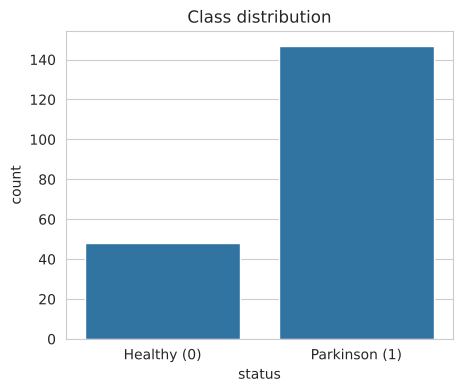

In [4]:
fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(x='status', data=df, ax=ax)
ax.set_xticklabels(['Healthy (0)', 'Parkinson (1)'])
ax.set_title('Class distribution')
plt.show()

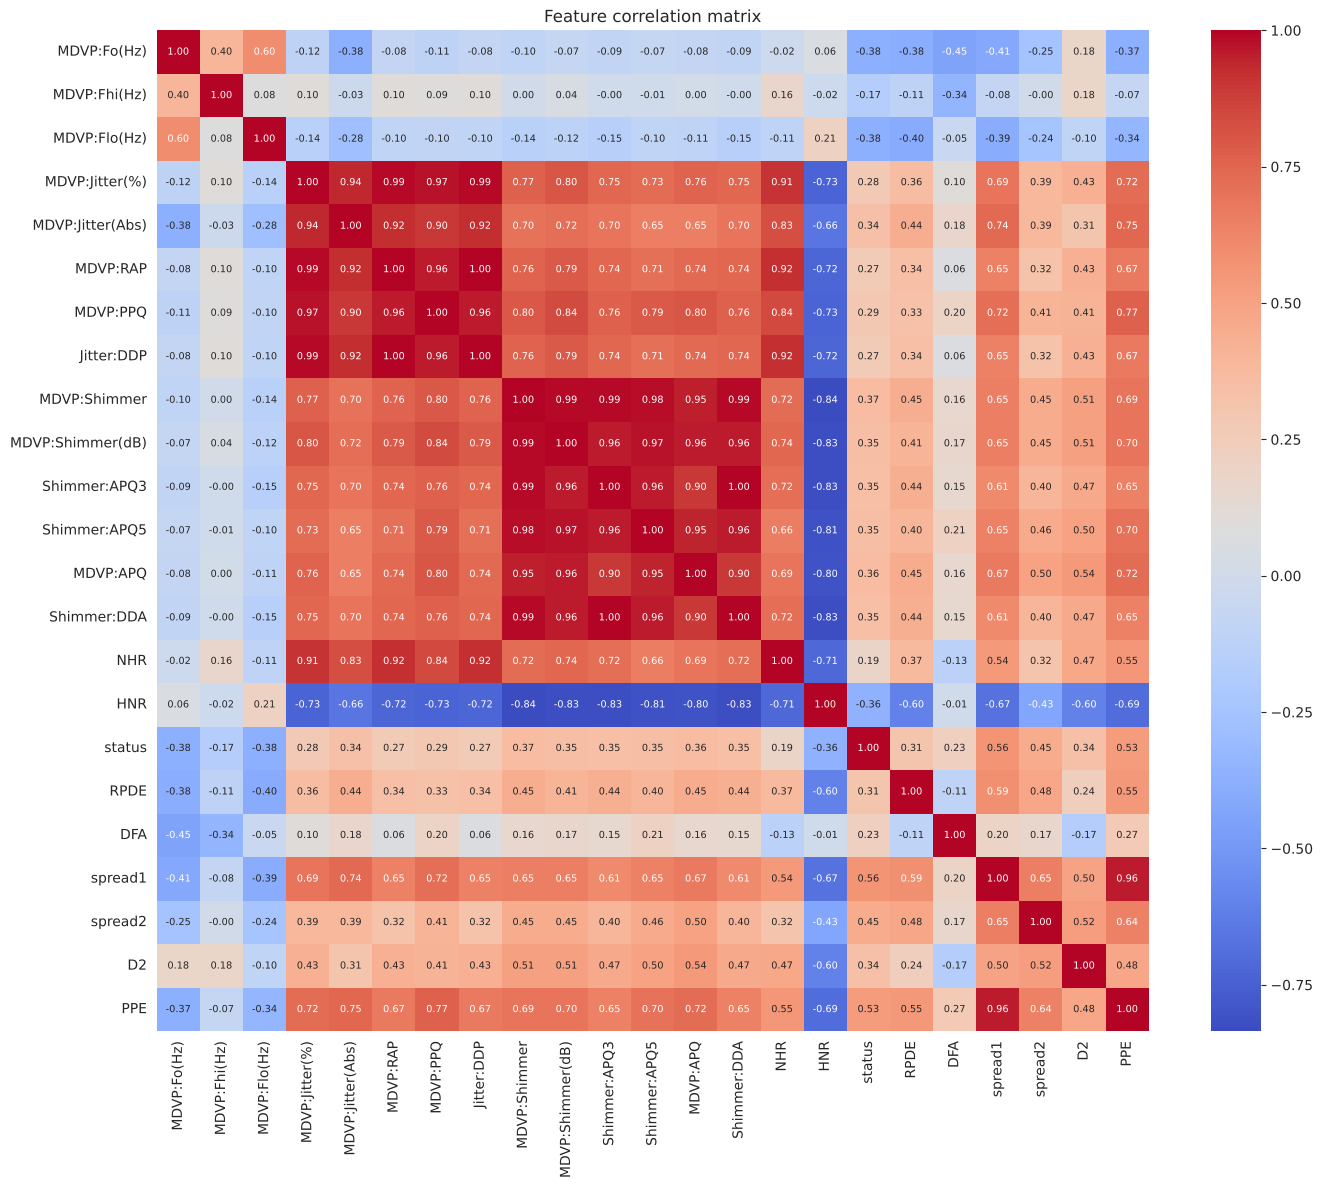

In [5]:
fig, ax = plt.subplots(figsize=(16, 13))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm', annot_kws={'size': 7}, ax=ax)
ax.set_title('Feature correlation matrix')
plt.show()

Jitter and shimmer measures are almost perfectly correlated with each other (r > 0.9). This motivates the group-wise feature engineering in Section 4 instead of dropping features one by one.

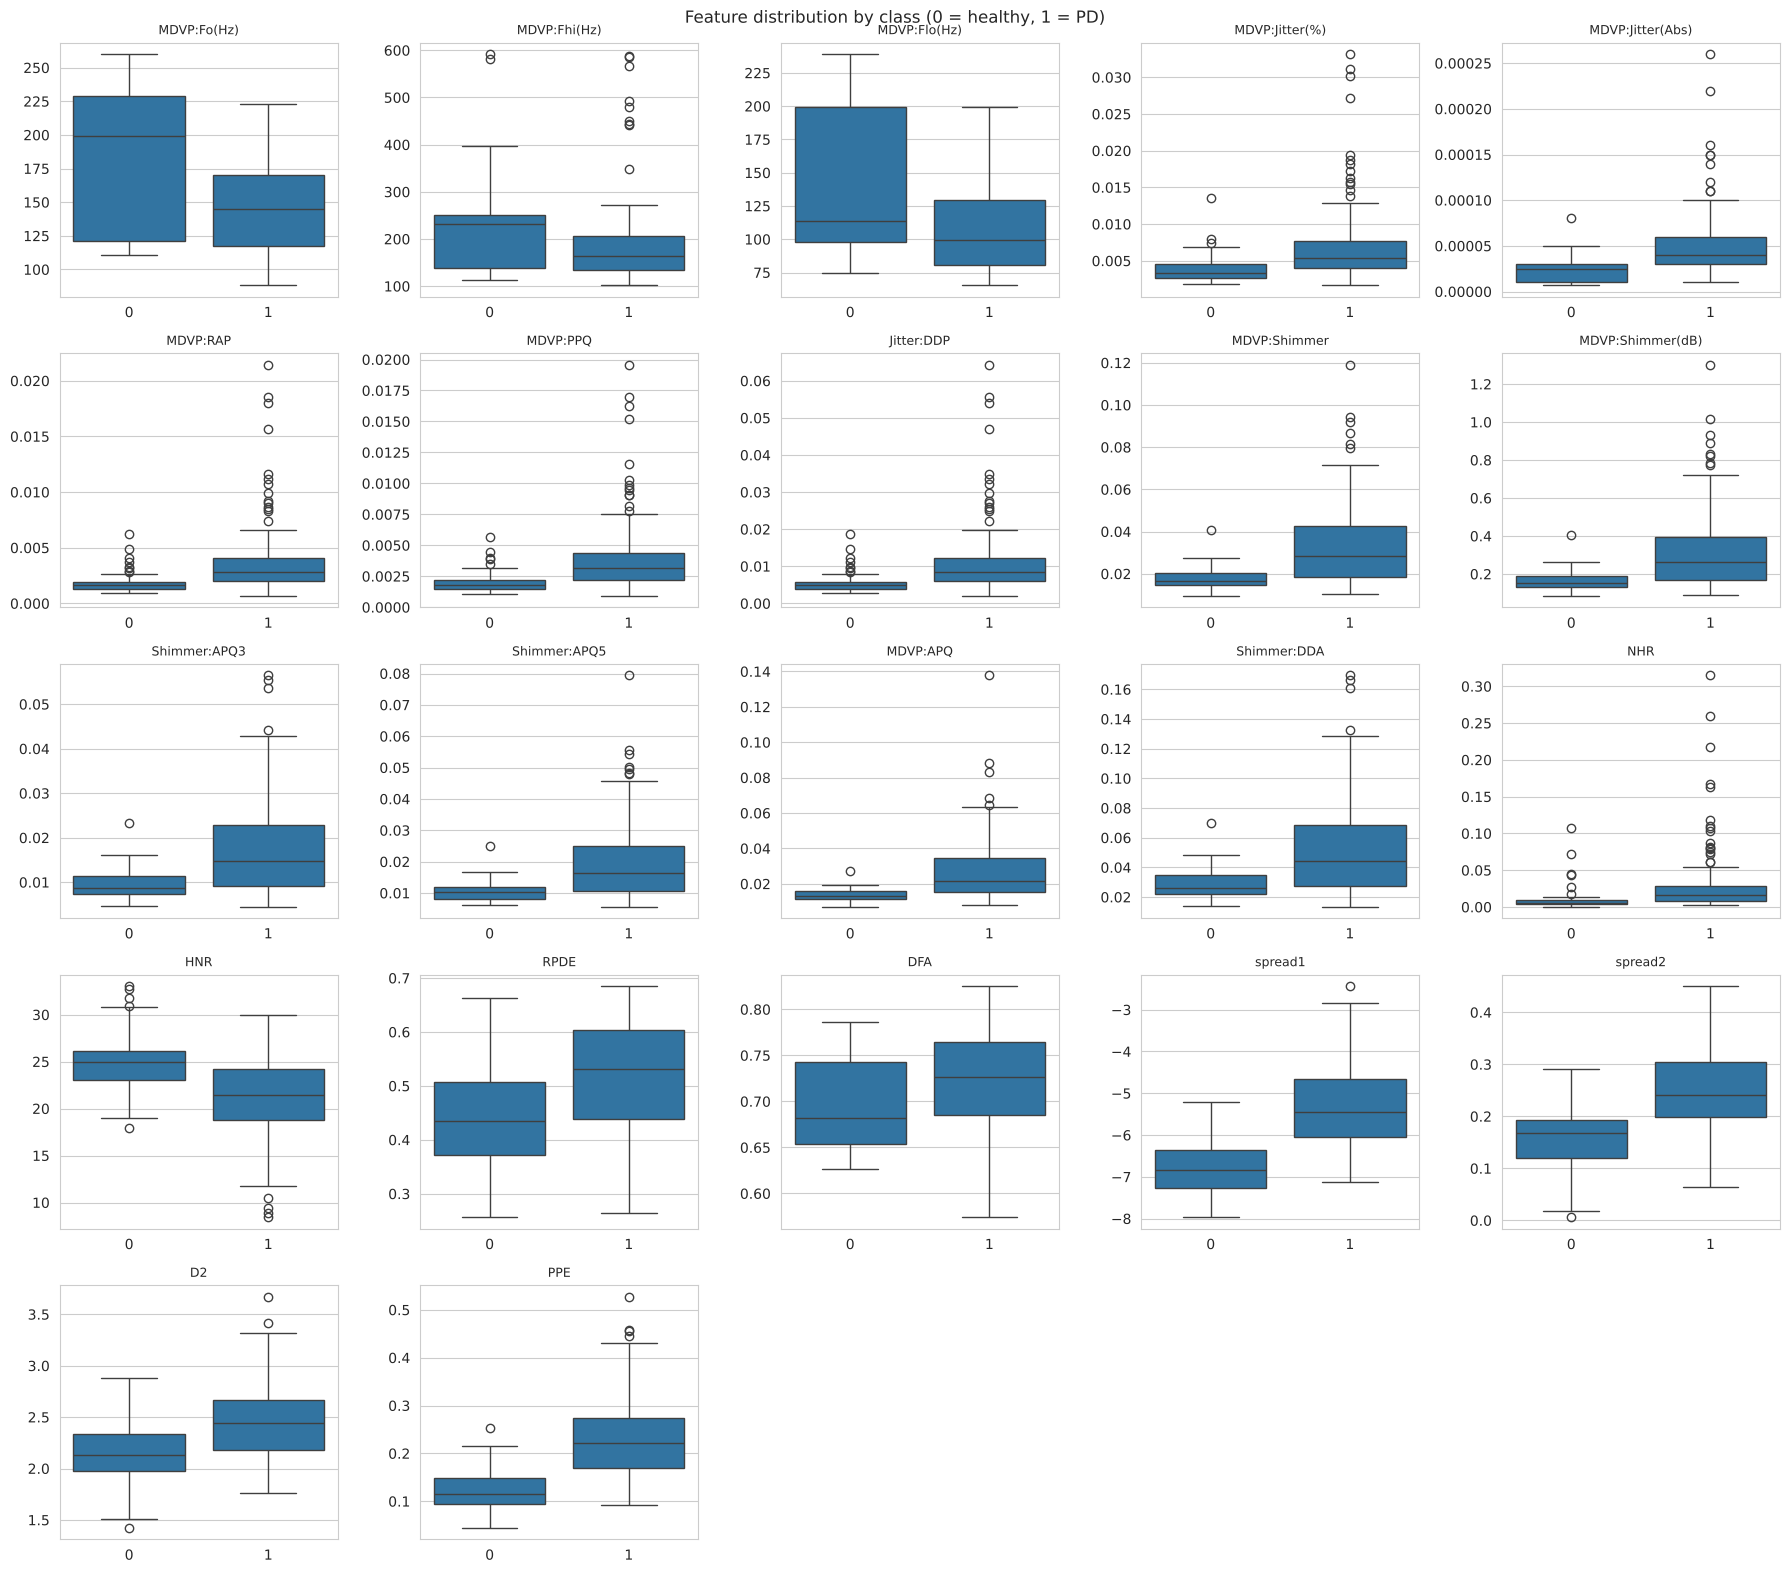

In [6]:
features = df.columns.drop('status')
fig, axes = plt.subplots(5, 5, figsize=(18, 16))
for ax, col in zip(axes.flatten(), features):
    sns.boxplot(x='status', y=col, data=df, ax=ax)
    ax.set_title(col, fontsize=9); ax.set_xlabel(''); ax.set_ylabel('')
for ax in axes.flatten()[len(features):]:
    ax.axis('off')
plt.suptitle('Feature distribution by class (0 = healthy, 1 = PD)')
plt.tight_layout()
plt.show()

PD recordings show lower HNR and fundamental frequencies, and higher spread1, PPE, jitter and shimmer.

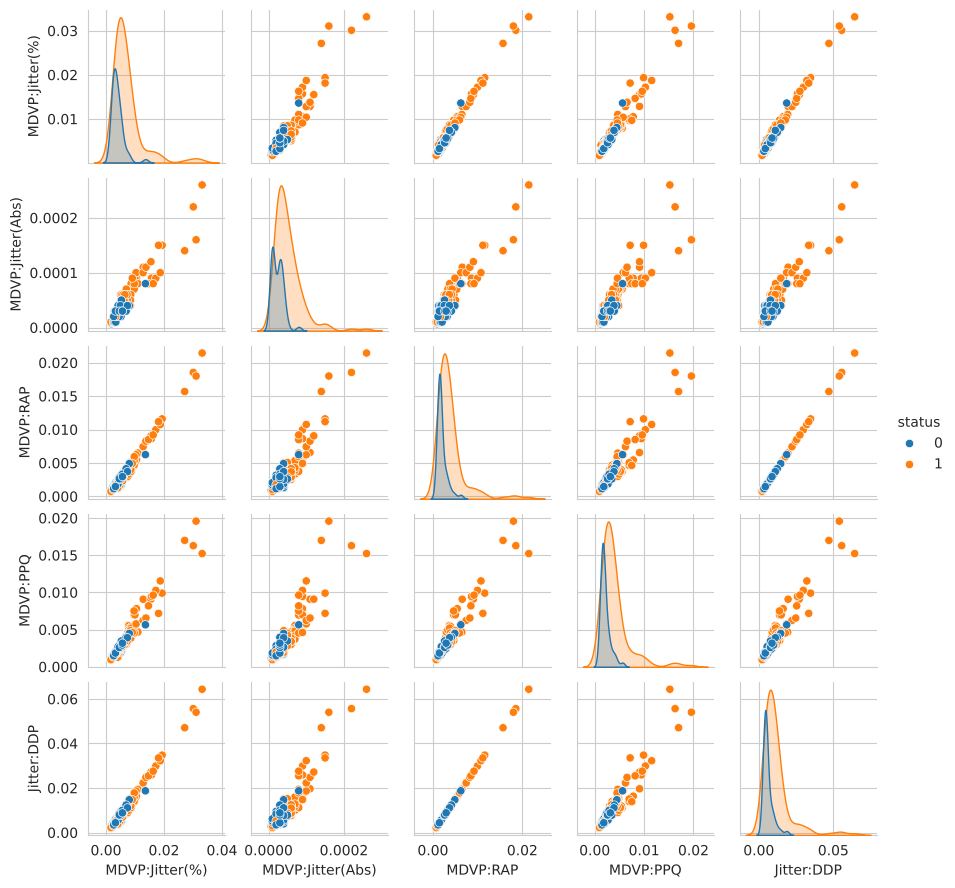

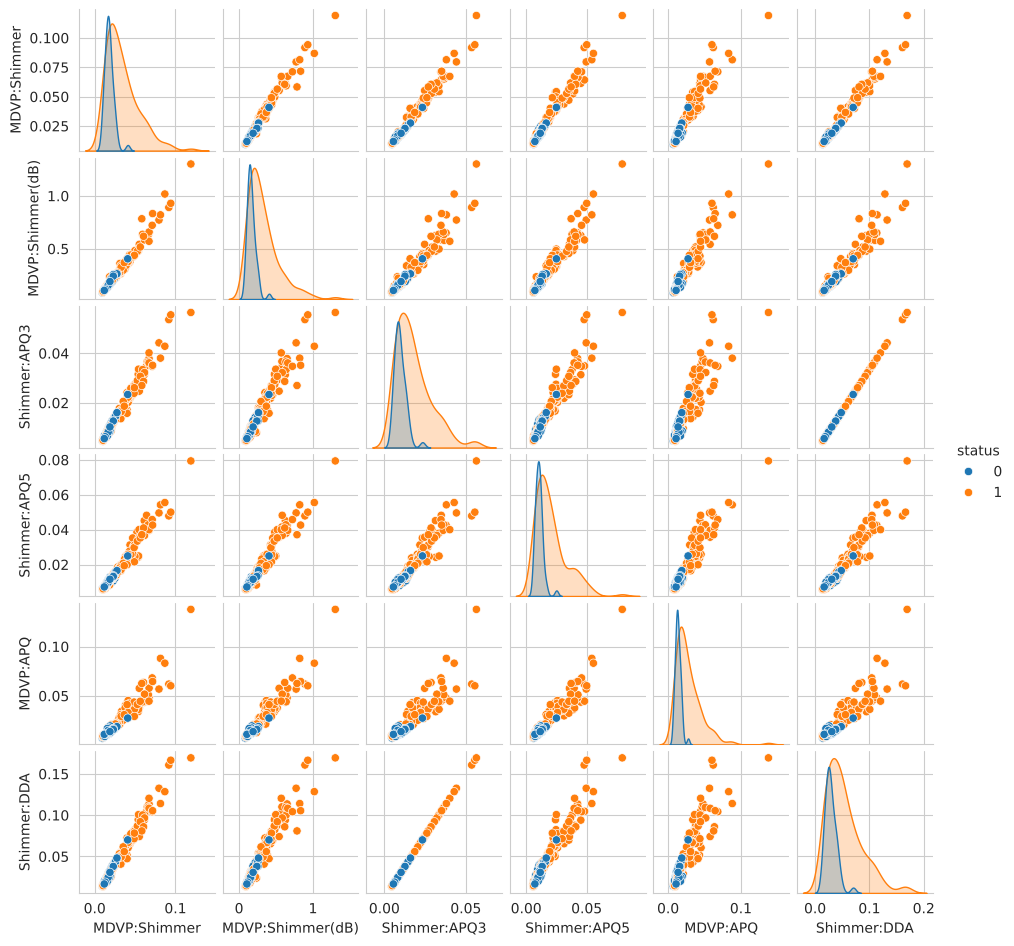

In [7]:
jitter_cols = ['MDVP:Jitter(%)', 'MDVP:Jitter(Abs)', 'MDVP:RAP', 'MDVP:PPQ', 'Jitter:DDP']
shimmer_cols = ['MDVP:Shimmer', 'MDVP:Shimmer(dB)', 'Shimmer:APQ3', 'Shimmer:APQ5', 'MDVP:APQ', 'Shimmer:DDA']
sns.pairplot(df, hue='status', vars=jitter_cols, height=1.8)
plt.show()
sns.pairplot(df, hue='status', vars=shimmer_cols, height=1.6)
plt.show()

## 4. Feature Engineering and Preprocessing

### 4.1 Geometric-mean biomedical feature groups
The 5 jitter, 6 shimmer and 3 nonlinear (RPDE, DFA, D2) features are each replaced by their geometric mean. The geometric mean suits positive ratio-scale measurements and keeps one value per biological group, reducing 22 features to 11.

In [8]:
nonlinear_cols = ['RPDE', 'DFA', 'D2']

def geometric_mean_feature(frame, cols, new_col):
    frame[new_col] = np.exp(np.log(frame[cols].clip(lower=1e-10)).mean(axis=1))
    return frame

df_eng = df.copy()
df_eng = geometric_mean_feature(df_eng, jitter_cols, 'Jitter_GeoMean')
df_eng = geometric_mean_feature(df_eng, shimmer_cols, 'Shimmer_GeoMean')
df_eng = geometric_mean_feature(df_eng, nonlinear_cols, 'Nonlinear_GeoMean')
df_eng = df_eng.drop(columns=jitter_cols + shimmer_cols + nonlinear_cols)

X_df = df_eng.drop(columns='status')
y = df_eng['status'].astype(int).values
feature_names = list(X_df.columns)
print(f'{df.shape[1] - 1} original features -> {len(feature_names)} engineered features')
print(feature_names)

22 original features -> 11 engineered features
['MDVP:Fo(Hz)', 'MDVP:Fhi(Hz)', 'MDVP:Flo(Hz)', 'NHR', 'HNR', 'spread1', 'spread2', 'PPE', 'Jitter_GeoMean', 'Shimmer_GeoMean', 'Nonlinear_GeoMean']


### 4.2 Normality test (Shapiro-Wilk)

In [9]:
sw = pd.DataFrame([{'Feature': c, 'W': shapiro(X_df[c])[0], 'p-value': shapiro(X_df[c])[1]} for c in feature_names])
sw['Normal (p > 0.05)?'] = np.where(sw['p-value'] > 0.05, 'Yes', 'No')
display(sw.round(5))
print(f"Features failing normality: {(sw['Normal (p > 0.05)?'] == 'No').sum()} / {len(sw)}")

,Feature,W,p-value,Normal (p > 0.05)?
0,MDVP:Fo(Hz),0.93705,0.00000,No
1,MDVP:Fhi(Hz),0.72284,0.00000,No
2,MDVP:Flo(Hz),0.86084,0.00000,No
3,NHR,0.52335,0.00000,No
4,HNR,0.97219,0.00064,No
5,spread1,0.98400,0.02568,No
6,spread2,0.99424,0.65444,Yes
7,PPE,0.95635,0.00001,No
8,Jitter_GeoMean,0.68619,0.00000,No
9,Shimmer_GeoMean,0.82749,0.00000,No


Features failing normality: 9 / 11


### 4.3 Yeo-Johnson power transform
Most features are skewed, and `spread1` is negative, so Yeo-Johnson (which accepts negative values, unlike Box-Cox) is used. It also standardises each feature.

In [10]:
pt = PowerTransformer(method='yeo-johnson', standardize=True)
X_yj = pt.fit_transform(X_df)

skew = pd.DataFrame({'Before': X_df.skew(), 'After': pd.DataFrame(X_yj, columns=feature_names).skew()}).round(3)
display(skew)
print(f"Mean |skew|: {skew['Before'].abs().mean():.3f} -> {skew['After'].abs().mean():.3f}")

,Before,After
MDVP:Fo(Hz),0.592,0.043
MDVP:Fhi(Hz),2.542,0.070
MDVP:Flo(Hz),1.217,0.106
NHR,4.221,0.691
HNR,-0.514,0.004
spread1,0.432,0.054
spread2,0.144,-0.000
PPE,0.797,0.045
Jitter_GeoMean,3.102,0.315
Shimmer_GeoMean,1.768,0.291


Mean |skew|: 1.402 -> 0.147


### 4.4 BorderlineSMOTE balancing and train/test split
BorderlineSMOTE creates synthetic healthy samples near the class boundary. The balanced data is then split 80/20 (stratified).

In [11]:
sm = BorderlineSMOTE(random_state=23, kind='borderline-1', m_neighbors=10)
X_bal, y_bal = sm.fit_resample(X_yj, y)
print('Before balancing:', dict(zip(*np.unique(y, return_counts=True))))
print('After balancing :', dict(zip(*np.unique(y_bal, return_counts=True))))

X_features, Y_labels = X_bal, np.asarray(y_bal).astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X_features, Y_labels, test_size=0.20, stratify=Y_labels, random_state=23)
print('Train:', X_train.shape, ' Test:', X_test.shape)

Before balancing: {np.int64(0): np.int64(48), np.int64(1): np.int64(147)}
After balancing : {np.int64(0): np.int64(147), np.int64(1): np.int64(147)}
Train: (235, 11)  Test: (59, 11)


## 5. Model Training

### 5.1 Decision Tree
Interpretable rule-based baseline.

In [12]:
dt_clf = DecisionTreeClassifier(criterion='entropy', max_depth=5, min_samples_split=4,
                                min_samples_leaf=2, random_state=23).fit(X_train, y_train)

### 5.2 Modified Hybrid Oblique Random Forest
A standard RF only makes axis-aligned splits (`x_j < t`). This version adds oblique features before training the forest: pairwise products and absolute differences of the 5 most relevant features (ranked by 0.65·ANOVA + 0.35·MI), and a projection on the class-mean difference direction. Trees can then split on multi-feature voice patterns.

In [13]:
class HybridObliqueRandomForest(BaseEstimator, ClassifierMixin):
    def __init__(self, n_estimators=200, max_depth=10, min_samples_leaf=2, max_features=0.5, random_state=42):
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.max_features = max_features
        self.random_state = random_state

    def _augment(self, X):
        X = np.asarray(X, dtype=float)
        T = X[:, self.top_idx_]
        pairs = [(a, b) for a in range(T.shape[1]) for b in range(a + 1, T.shape[1])]
        inter = np.column_stack([T[:, a] * T[:, b] for a, b in pairs])
        diff = np.column_stack([np.abs(T[:, a] - T[:, b]) for a, b in pairs])
        return np.hstack([X, inter, diff, (X @ self.class_projection_)[:, None]])

    def fit(self, X, y):
        X = np.asarray(X, dtype=float); y = np.asarray(y).astype(int)
        self.classes_ = np.unique(y)
        f = np.nan_to_num(f_classif(X, y)[0])
        mi = np.nan_to_num(mutual_info_classif(X, y, random_state=self.random_state))
        self.relevance_ = 0.65 * f / (f.sum() + 1e-12) + 0.35 * mi / (mi.sum() + 1e-12)
        self.top_idx_ = np.argsort(self.relevance_)[::-1][:min(5, X.shape[1])]
        v = X[y == 1].mean(axis=0) - X[y == 0].mean(axis=0)
        self.class_projection_ = v / (np.linalg.norm(v) + 1e-12)
        self.rf_ = RandomForestClassifier(n_estimators=self.n_estimators, max_depth=self.max_depth,
                                          min_samples_leaf=self.min_samples_leaf, max_features=self.max_features,
                                          class_weight='balanced_subsample', random_state=self.random_state, n_jobs=-1)
        self.rf_.fit(self._augment(X), y)
        return self

    def predict_proba(self, X):
        return self.rf_.predict_proba(self._augment(X))

    def predict(self, X):
        return self.rf_.predict(self._augment(X))


rf_grid = GridSearchCV(HybridObliqueRandomForest(random_state=RANDOM_STATE),
                       {'n_estimators': [150, 200], 'max_depth': [8, 10, None],
                        'max_features': [0.5, 'sqrt'], 'min_samples_leaf': [1, 2]},
                       cv=5, scoring='accuracy', n_jobs=-1).fit(X_train, y_train)
rfc1 = rf_grid.best_estimator_
print('Best Hybrid RF params:', rf_grid.best_params_)

Best Hybrid RF params: {'max_depth': 8, 'max_features': 0.5, 'min_samples_leaf': 2, 'n_estimators': 150}


### 5.3 Logistic Regression
Linear, interpretable benchmark.

In [14]:
logmodel = LogisticRegression(max_iter=500).fit(X_train, y_train)

### 5.4 Support Vector Machine (GridSearch over linear and RBF kernels)
The RBF kernel captures curved boundaries between interacting voice features. The grid picks the kernel, C and gamma by 5-fold CV.

In [15]:
grid_SVC = GridSearchCV(SVC(probability=True, random_state=RANDOM_STATE),
                        {'kernel': ['linear', 'rbf'], 'C': [0.1, 0.5, 1, 2], 'gamma': ['scale', 0.01]},
                        cv=5, scoring='accuracy', n_jobs=-1).fit(X_train, y_train)
svm_clf = grid_SVC.best_estimator_
print('Best SVM params:', grid_SVC.best_params_)

Best SVM params: {'C': 2, 'gamma': 'scale', 'kernel': 'rbf'}


### 5.5 Proposed ANOVA-MI Weighted Hybrid KNN
Plain KNN uses Euclidean distance, which treats every feature as equally important. The hybrid distance is

$$D(x,z)=\alpha\sqrt{\sum_j w_j(x_j-z_j)^2}+\beta\,(1-\cos(x,z))+\gamma\sum_j w_j|x_j-z_j|$$

with feature weights $w_j = 0.65\cdot\text{ANOVA-F}_j + 0.35\cdot\text{MI}_j$ (each normalised), and neighbour votes weighted by $1/d^{p}$. Mahalanobis distance was tried earlier and was unstable on 195 samples.

In [16]:
class AnovaMIHybridKNN(BaseEstimator, ClassifierMixin):
    def __init__(self, n_neighbors=3, alpha=1.0, beta=0.10, gamma=0.20,
                 mi_weight=0.35, anova_weight=0.65, distance_power=3.0, eps=1e-8, random_state=42):
        self.n_neighbors = n_neighbors
        self.alpha = alpha
        self.beta = beta
        self.gamma = gamma
        self.mi_weight = mi_weight
        self.anova_weight = anova_weight
        self.distance_power = distance_power
        self.eps = eps
        self.random_state = random_state

    def fit(self, X, y):
        self.X_train_ = np.asarray(X, dtype=float)
        self.y_train_ = np.asarray(y).astype(int)
        self.classes_ = np.unique(self.y_train_)
        f = np.nan_to_num(f_classif(self.X_train_, self.y_train_)[0])
        mi = np.nan_to_num(mutual_info_classif(self.X_train_, self.y_train_, random_state=self.random_state))
        w = self.anova_weight * f / (f.sum() + self.eps) + self.mi_weight * mi / (mi.sum() + self.eps)
        self.feature_weights_ = w / (w.sum() + self.eps)
        return self

    def _distances(self, X):
        X = np.asarray(X, dtype=float)
        diff = X[:, None, :] - self.X_train_[None, :, :]
        w_euclid = np.sqrt(np.sum(self.feature_weights_ * diff ** 2, axis=2))
        w_manhattan = np.sum(self.feature_weights_ * np.abs(diff), axis=2)
        cos = (X @ self.X_train_.T) / ((np.linalg.norm(X, axis=1, keepdims=True) + self.eps) *
                                        (np.linalg.norm(self.X_train_, axis=1)[None, :] + self.eps))
        return self.alpha * w_euclid + self.beta * (1 - np.clip(cos, -1, 1)) + self.gamma * w_manhattan

    def predict_proba(self, X):
        D = self._distances(X)
        idx = np.argsort(D, axis=1)[:, :self.n_neighbors]
        d = np.take_along_axis(D, idx, axis=1)
        votes = 1.0 / (d + self.eps) ** self.distance_power
        labels = self.y_train_[idx]
        scores = np.column_stack([(votes * (labels == c)).sum(axis=1) for c in self.classes_])
        return scores / (scores.sum(axis=1, keepdims=True) + self.eps)

    def predict(self, X):
        return self.classes_[np.argmax(self.predict_proba(X), axis=1)]


hybrid_knn = AnovaMIHybridKNN(random_state=RANDOM_STATE).fit(X_train, y_train)

### 5.6 XGBoost with Bayesian hyperparameter optimisation
`BayesSearchCV` uses earlier trials to choose the next hyperparameters, so it explores the space more efficiently than grid or random search.

In [17]:
xgb_search = BayesSearchCV(
    XGBClassifier(objective='binary:logistic', eval_metric='logloss', random_state=RANDOM_STATE, verbosity=0),
    {'n_estimators': Integer(80, 400), 'max_depth': Integer(2, 6),
     'learning_rate': Real(0.01, 0.25, prior='log-uniform'), 'subsample': Real(0.75, 1.0),
     'colsample_bytree': Real(0.75, 1.0), 'reg_lambda': Real(0.5, 3.0, prior='log-uniform'),
     'reg_alpha': Real(0.0, 1.0)},
    n_iter=25, scoring='f1', cv=5, random_state=RANDOM_STATE, n_jobs=-1).fit(X_train, y_train)
xgb_clf = xgb_search.best_estimator_
print('Best CV F1:', round(xgb_search.best_score_, 4))
print('Best params:', dict(xgb_search.best_params_))

Best CV F1: 0.9571
Best params: {'colsample_bytree': 0.9246036538584219, 'learning_rate': 0.07200921123769392, 'max_depth': 5, 'n_estimators': 352, 'reg_alpha': 0.6725506445671087, 'reg_lambda': 1.65398103352768, 'subsample': 0.806875184536062}


### 5.7 Extra Trees, Stacking and Uncertainty-Aware Ensemble
* **Extra Trees**: randomised split thresholds, lower variance than RF.
* **Stacking**: SVM + Hybrid RF + XGBoost, combined by a logistic-regression meta-learner.
* **Uncertainty-aware ensemble**: for each sample, every model is weighted by the inverse of its prediction entropy, so confident models count more.

In [18]:
etc = ExtraTreesClassifier(n_estimators=100, random_state=42).fit(X_train, y_train)

stack = StackingClassifier(estimators=[('svm', svm_clf), ('rf', rfc1), ('xgb', xgb_clf)],
                           final_estimator=LogisticRegression(), cv=5).fit(X_train, y_train)


class UncertaintyAwareEnsemble(BaseEstimator, ClassifierMixin):
    # Combines already-fitted models; weight = 1 / Shannon entropy of each model's prediction
    def __init__(self, estimators, epsilon=1e-9):
        self.estimators = estimators
        self.epsilon = epsilon

    def fit(self, X, y):
        self.classes_ = np.unique(y)
        return self

    def predict_proba(self, X):
        weighted, total = 0, 0
        for _, est in self.estimators:
            p = est.predict_proba(X)
            pc = np.clip(p, self.epsilon, 1 - self.epsilon)
            w = 1.0 / (-np.sum(pc * np.log2(pc), axis=1) + self.epsilon)
            weighted = weighted + w[:, None] * p
            total = total + w
        return weighted / total[:, None]

    def predict(self, X):
        return self.classes_[np.argmax(self.predict_proba(X), axis=1)]


ua_ensemble = UncertaintyAwareEnsemble([('dt', dt_clf), ('rf', rfc1), ('lr', logmodel), ('svm', svm_clf),
                                        ('xgb', xgb_clf), ('stack', stack), ('et', etc),
                                        ('hybrid_knn', hybrid_knn)]).fit(X_train, y_train)

## 6. Evaluation and Comparison
### 6.1 Test-set metrics

In [19]:
models = {
    'Decision Tree': dt_clf, 'Hybrid RF': rfc1, 'Logistic Reg': logmodel, 'SVM (RBF)': svm_clf,
    'XGB (Bayesian)': xgb_clf, 'Extra Trees': etc, 'Stacking': stack,
    'Hybrid KNN': hybrid_knn, 'UA Ensemble': ua_ensemble,
}

def evaluate(name, model, Xte=X_test, yte=y_test):
    pred = model.predict(Xte)
    proba = model.predict_proba(Xte)[:, 1]
    tn, fp, fn, tp = confusion_matrix(yte, pred).ravel()
    sens, spec = tp / (tp + fn), tn / (tn + fp)
    return {'Model': name, 'Accuracy': accuracy_score(yte, pred), 'Precision': precision_score(yte, pred),
            'Recall/Sensitivity': sens, 'Specificity': spec, 'F1': f1_score(yte, pred),
            'MCC': matthews_corrcoef(yte, pred), 'Kappa': cohen_kappa_score(yte, pred),
            "Youden's J": sens + spec - 1, 'ROC-AUC': roc_auc_score(yte, proba),
            'Brier': brier_score_loss(yte, proba)}

results = pd.DataFrame([evaluate(n, m) for n, m in models.items()]).sort_values('MCC', ascending=False)
display(results.round(4).reset_index(drop=True))

,Model,Accuracy,Precision,Recall/Sensitivity,Specificity,F1,MCC,Kappa,Youden's J,ROC-AUC,Brier
0,UA Ensemble,0.9831,1.0000,0.9667,1.0000,0.9831,0.9667,0.9661,0.9667,0.9954,0.0271
1,Extra Trees,0.9831,1.0000,0.9667,1.0000,0.9831,0.9667,0.9661,0.9667,0.9994,0.0266
2,Stacking,0.9831,0.9677,1.0000,0.9655,0.9836,0.9666,0.9661,0.9655,0.9989,0.0184
3,Hybrid RF,0.9831,0.9677,1.0000,0.9655,0.9836,0.9666,0.9661,0.9655,0.9989,0.0360
4,XGB (Bayesian),0.9831,0.9677,1.0000,0.9655,0.9836,0.9666,0.9661,0.9655,0.9966,0.0206
5,Hybrid KNN,0.9492,1.0000,0.9000,1.0000,0.9474,0.9031,0.8985,0.9000,0.9828,0.0344
6,SVM (RBF),0.9492,1.0000,0.9000,1.0000,0.9474,0.9031,0.8985,0.9000,0.9931,0.0311
7,Decision Tree,0.9153,0.9310,0.9000,0.9310,0.9153,0.8310,0.8306,0.8310,0.9569,0.0593
8,Logistic Reg,0.7966,0.8462,0.7333,0.8621,0.7857,0.5996,0.5940,0.5954,0.8563,0.1453


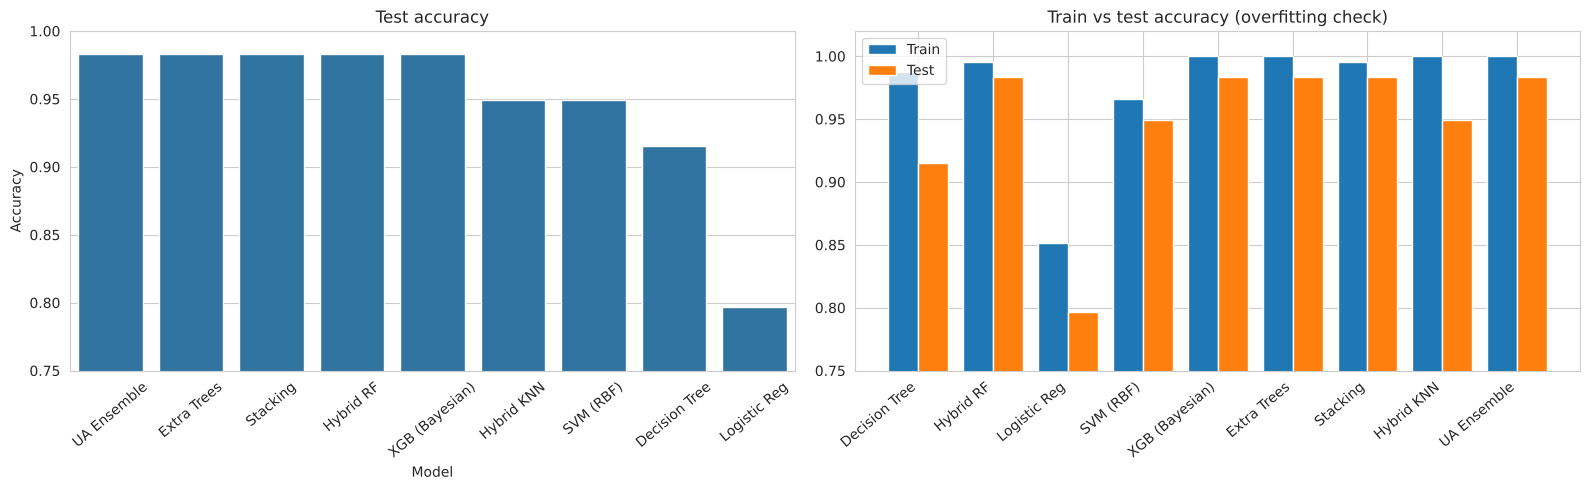

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
r = results.sort_values('Accuracy', ascending=False)
sns.barplot(x='Model', y='Accuracy', data=r, ax=ax[0])
ax[0].set_ylim(0.75, 1.0); ax[0].set_title('Test accuracy'); ax[0].tick_params(axis='x', rotation=40)

train_acc = [accuracy_score(y_train, m.predict(X_train)) for m in models.values()]
test_acc = [accuracy_score(y_test, m.predict(X_test)) for m in models.values()]
x = np.arange(len(models))
ax[1].bar(x - 0.2, train_acc, 0.4, label='Train'); ax[1].bar(x + 0.2, test_acc, 0.4, label='Test')
ax[1].set_xticks(x); ax[1].set_xticklabels(models.keys(), rotation=40, ha='right')
ax[1].set_ylim(0.75, 1.02); ax[1].set_title('Train vs test accuracy (overfitting check)'); ax[1].legend()
plt.tight_layout(); plt.show()

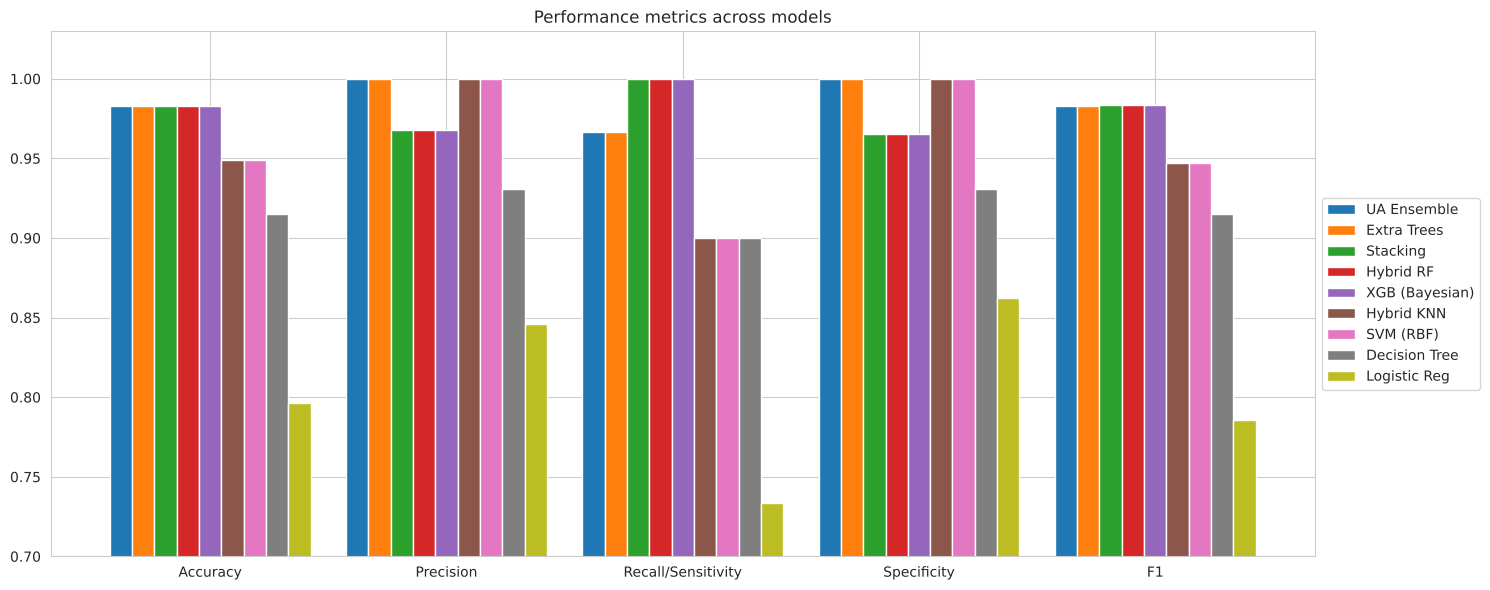

In [21]:
metric_cols = ['Accuracy', 'Precision', 'Recall/Sensitivity', 'Specificity', 'F1']
results.set_index('Model')[metric_cols].T.plot(kind='bar', figsize=(15, 6), width=0.85)
plt.ylim(0.7, 1.03); plt.xticks(rotation=0)
plt.title('Performance metrics across models'); plt.legend(bbox_to_anchor=(1, 0.5), loc='center left')
plt.tight_layout(); plt.show()

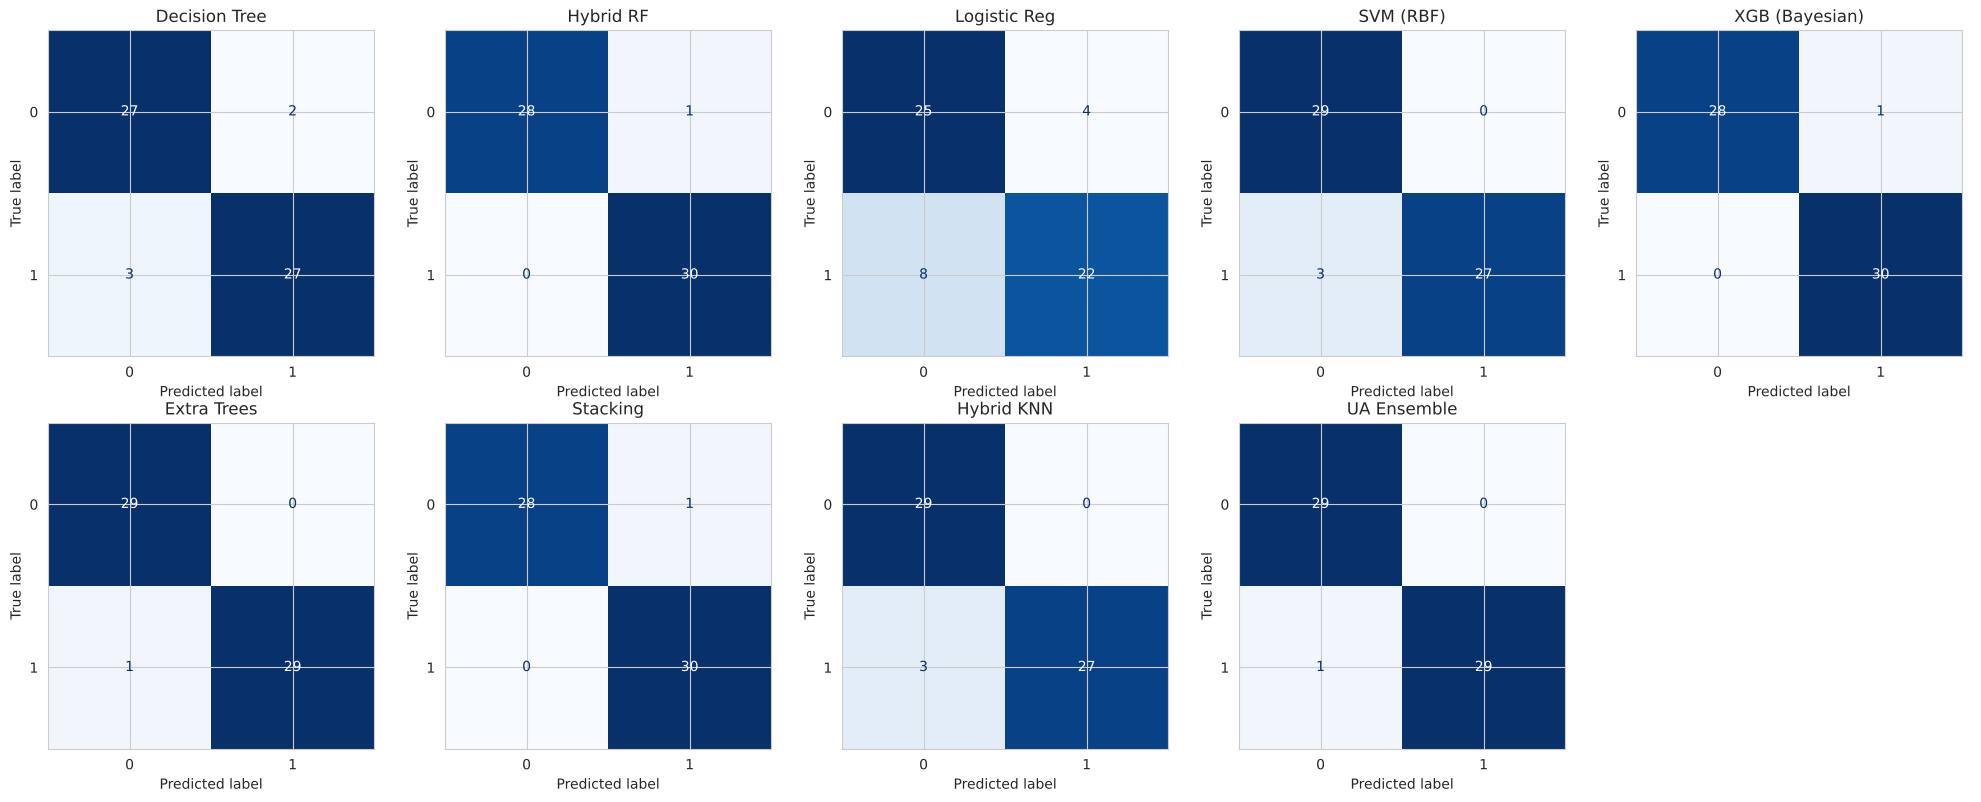

In [22]:
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
for ax, (name, m) in zip(axes.flatten(), models.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, m.predict(X_test), cmap='Blues', ax=ax, colorbar=False)
    ax.set_title(name)
axes.flatten()[-1].axis('off')
plt.tight_layout(); plt.show()

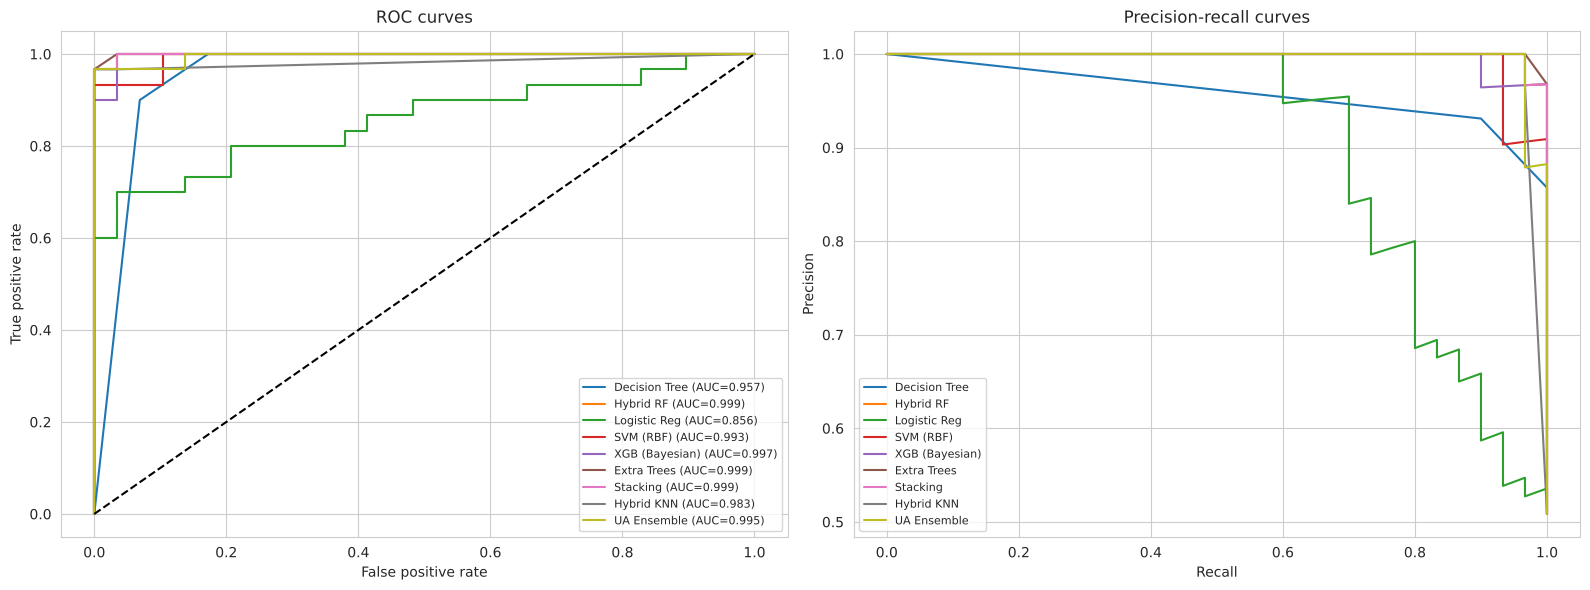

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
for name, m in models.items():
    p = m.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, p)
    ax[0].plot(fpr, tpr, label=f'{name} (AUC={roc_auc_score(y_test, p):.3f})')
    prec, rec, _ = precision_recall_curve(y_test, p)
    ax[1].plot(rec, prec, label=name)
ax[0].plot([0, 1], [0, 1], 'k--'); ax[0].set(xlabel='False positive rate', ylabel='True positive rate', title='ROC curves')
ax[1].set(xlabel='Recall', ylabel='Precision', title='Precision-recall curves')
ax[0].legend(fontsize=8); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

### 6.2 10-fold cross-validation and significance tests

In [24]:
cv10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
cv_models = {
    'Decision Tree': DecisionTreeClassifier(criterion='entropy', max_depth=5, min_samples_split=4, min_samples_leaf=2, random_state=23),
    'Hybrid RF': HybridObliqueRandomForest(random_state=RANDOM_STATE),
    'Logistic Reg': LogisticRegression(max_iter=500),
    'SVM (RBF)': svm_clf,
    'XGB (Bayesian)': xgb_clf,
    'Extra Trees': ExtraTreesClassifier(n_estimators=100, random_state=42),
    'Hybrid KNN': AnovaMIHybridKNN(random_state=RANDOM_STATE),
}
all_cv_scores = {n: cross_val_score(m, X_features, Y_labels, cv=cv10, scoring='accuracy', n_jobs=-1)
                 for n, m in cv_models.items()}
cv_summary = pd.DataFrame([{'Model': n, 'Mean (%)': s.mean() * 100, 'Std (%)': s.std() * 100,
                            'Min (%)': s.min() * 100, 'Max (%)': s.max() * 100}
                           for n, s in all_cv_scores.items()]).sort_values('Mean (%)', ascending=False)
display(cv_summary.round(2).reset_index(drop=True))

best = cv_summary.iloc[0]['Model']
rows = []
for n, s in all_cv_scores.items():
    if n == best:
        continue
    t_p = ttest_rel(all_cv_scores[best], s).pvalue
    try:
        w_p = wilcoxon(all_cv_scores[best], s).pvalue
    except ValueError:
        w_p = np.nan
    rows.append({'Best': best, 'Compared with': n, 't-test p': t_p, 'Wilcoxon p': w_p,
                 'Significant (p<0.05)?': 'Yes' if min(t_p, np.nan_to_num(w_p, nan=1)) < 0.05 else 'No'})
display(pd.DataFrame(rows).round(4))

,Model,Mean (%),Std (%),Min (%),Max (%)
0,Extra Trees,97.64,3.03,93.10,100.00
1,XGB (Bayesian),96.28,2.79,90.00,100.00
2,Hybrid RF,96.26,2.36,93.10,100.00
3,Hybrid KNN,94.54,3.83,89.66,100.00
4,SVM (RBF),93.86,5.50,82.76,100.00
5,Decision Tree,93.24,4.18,83.33,96.67
6,Logistic Reg,80.93,5.59,72.41,89.66


,Best,Compared with,t-test p,Wilcoxon p,Significant (p<0.05)?
0,Extra Trees,Decision Tree,0.0087,0.0078,Yes
1,Extra Trees,Hybrid RF,0.0994,0.0938,No
2,Extra Trees,Logistic Reg,0.0000,0.0020,Yes
3,Extra Trees,SVM (RBF),0.0322,0.0312,Yes
4,Extra Trees,XGB (Bayesian),0.1005,0.1250,No
5,Extra Trees,Hybrid KNN,0.0911,0.1406,No


## 7. Ablation: Normal vs Modified Models
Each modification is compared against its unmodified version on the same split and the same 10-fold CV.

In [25]:
def ablation(pairs):
    test_rows, cv_rows = [], []
    for name, model in pairs:
        test_rows.append(evaluate(name, model.fit(X_train, y_train)))
        acc = cross_val_score(model, X_features, Y_labels, cv=cv10, scoring='accuracy', n_jobs=-1)
        mcc = cross_val_score(model, X_features, Y_labels, cv=cv10, scoring='matthews_corrcoef', n_jobs=-1)
        cv_rows.append({'Model': name, 'CV Acc (%)': acc.mean() * 100, 'CV Std (%)': acc.std() * 100, 'CV MCC': mcc.mean()})
    display(pd.DataFrame(test_rows).round(4)); display(pd.DataFrame(cv_rows).round(4))

print('KNN: Euclidean vs Hybrid distance')
ablation([('Normal Euclidean KNN', KNeighborsClassifier(n_neighbors=3)),
          ('ANOVA-MI Hybrid KNN', AnovaMIHybridKNN(random_state=RANDOM_STATE))])
print('Random Forest: axis-aligned vs oblique')
ablation([('Normal RF', RandomForestClassifier(n_estimators=200, max_depth=10, min_samples_leaf=2, max_features=0.5, random_state=RANDOM_STATE, n_jobs=-1)),
          ('Hybrid Oblique RF', HybridObliqueRandomForest(random_state=RANDOM_STATE))])
print('XGBoost: default vs Bayesian-tuned')
ablation([('Default XGBoost', XGBClassifier(eval_metric='logloss', random_state=RANDOM_STATE, verbosity=0)),
          ('Bayesian XGBoost', XGBClassifier(eval_metric='logloss', random_state=RANDOM_STATE, verbosity=0, **dict(xgb_search.best_params_)))])

KNN: Euclidean vs Hybrid distance


,Model,Accuracy,Precision,Recall/Sensitivity,Specificity,F1,MCC,Kappa,Youden's J,ROC-AUC,Brier
0,Normal Euclidean KNN,0.8983,1.0,0.8,1.0,0.8889,0.8142,0.7973,0.8,0.9799,0.0621
1,ANOVA-MI Hybrid KNN,0.9492,1.0,0.9,1.0,0.9474,0.9031,0.8985,0.9,0.9828,0.0344


,Model,CV Acc (%),CV Std (%),CV MCC
0,Normal Euclidean KNN,92.4943,5.4788,0.8634
1,ANOVA-MI Hybrid KNN,94.5402,3.8306,0.8975


Random Forest: axis-aligned vs oblique


,Model,Accuracy,Precision,Recall/Sensitivity,Specificity,F1,MCC,Kappa,Youden's J,ROC-AUC,Brier
0,Normal RF,0.9831,0.9677,1.0000,0.9655,0.9836,0.9666,0.9661,0.9655,0.9989,0.0284
1,Hybrid Oblique RF,0.9661,0.9667,0.9667,0.9655,0.9667,0.9322,0.9322,0.9322,0.9989,0.0366


,Model,CV Acc (%),CV Std (%),CV MCC
0,Normal RF,96.2644,2.8170,0.9275
1,Hybrid Oblique RF,96.2644,2.3574,0.9279


XGBoost: default vs Bayesian-tuned


,Model,Accuracy,Precision,Recall/Sensitivity,Specificity,F1,MCC,Kappa,Youden's J,ROC-AUC,Brier
0,Default XGBoost,0.9831,0.9677,1.0,0.9655,0.9836,0.9666,0.9661,0.9655,1.0000,0.0092
1,Bayesian XGBoost,0.9831,0.9677,1.0,0.9655,0.9836,0.9666,0.9661,0.9655,0.9966,0.0206


,Model,CV Acc (%),CV Std (%),CV MCC
0,Default XGBoost,94.9080,3.1247,0.9018
1,Bayesian XGBoost,96.2759,2.7906,0.9277


## 8. Explainability
### 8.1 Chi-square feature relevance
Chi-square needs non-negative inputs, so features are min-max scaled for this test only.

,Feature,Chi2,p-value,Significant (p<0.05)?
0,Shimmer_GeoMean,9.02074,0.00267,Yes
1,PPE,5.96689,0.01458,Yes
2,spread1,5.94093,0.01479,Yes
3,spread2,5.84449,0.01563,Yes
4,Jitter_GeoMean,4.04616,0.04427,Yes
5,Nonlinear_GeoMean,3.72860,0.05349,No
6,NHR,3.33709,0.06773,No
7,MDVP:Fhi(Hz),1.84405,0.17448,No
8,HNR,1.50455,0.21997,No
9,MDVP:Fo(Hz),1.11526,0.29094,No


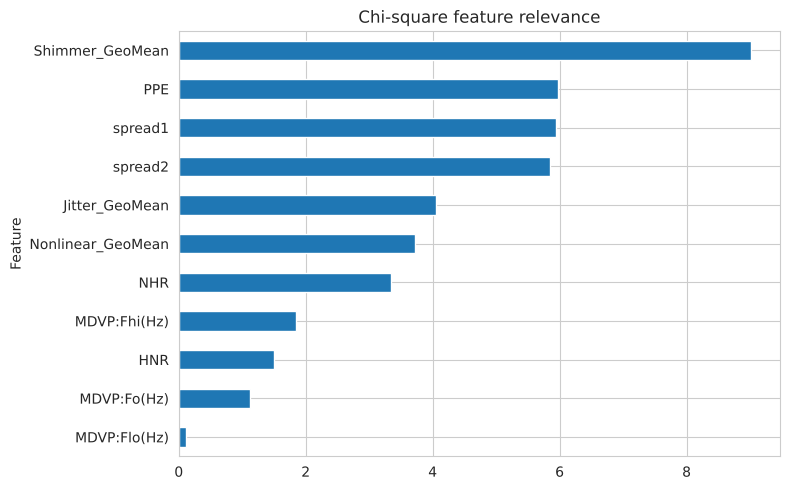

In [26]:
chi_scores, chi_p = chi2(MinMaxScaler().fit_transform(X_features), Y_labels)
chi_df = pd.DataFrame({'Feature': feature_names, 'Chi2': chi_scores, 'p-value': chi_p})
chi_df['Significant (p<0.05)?'] = np.where(chi_df['p-value'] < 0.05, 'Yes', 'No')
chi_df = chi_df.sort_values('Chi2', ascending=False).reset_index(drop=True)
display(chi_df.round(5))
chi_df.plot.barh(x='Feature', y='Chi2', figsize=(8, 5), legend=False, title='Chi-square feature relevance').invert_yaxis()
plt.tight_layout(); plt.show()

### 8.2 SHAP (global, Extra Trees)

,Feature,Mean |SHAP|
0,spread2,0.0883
1,MDVP:Fhi(Hz),0.0630
2,MDVP:Fo(Hz),0.0574
3,Shimmer_GeoMean,0.0508
4,PPE,0.0498
5,spread1,0.0491
6,Nonlinear_GeoMean,0.0368
7,MDVP:Flo(Hz),0.0351
8,Jitter_GeoMean,0.0228
9,NHR,0.0192


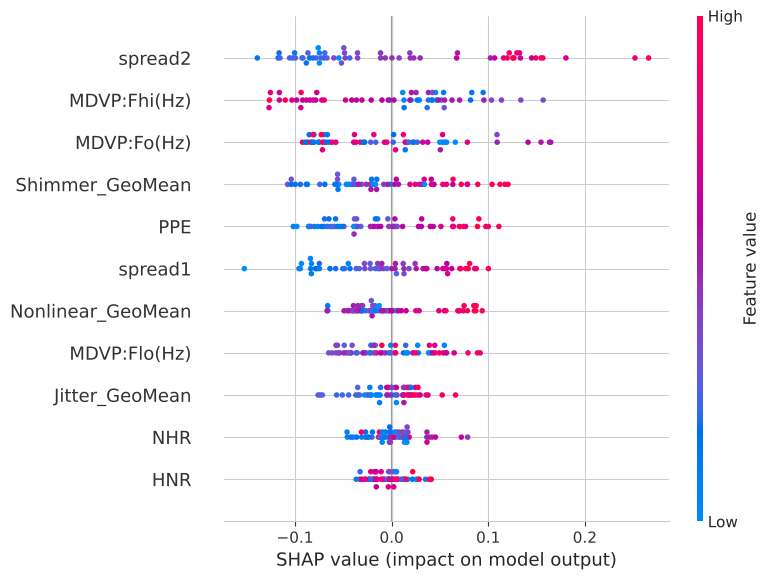

In [27]:
import shap
X_test_df = pd.DataFrame(X_test, columns=feature_names)
sv = shap.TreeExplainer(etc).shap_values(X_test_df)
sv1 = sv[1] if isinstance(sv, list) else (sv[:, :, 1] if np.ndim(sv) == 3 else sv)
display(pd.DataFrame({'Feature': feature_names, 'Mean |SHAP|': np.abs(sv1).mean(axis=0)})
        .sort_values('Mean |SHAP|', ascending=False).round(4).reset_index(drop=True))
shap.summary_plot(sv1, X_test_df, show=True)

### 8.3 LIME (local, one test recording, uncertainty-aware ensemble)

True class: Healthy | Predicted P(Parkinson): 0.0


,Condition,Contribution
0,MDVP:Fhi(Hz) > 0.91,-0.2965
1,spread2 <= -0.81,-0.2827
2,spread1 <= -0.69,-0.0681
3,MDVP:Fo(Hz) > 1.00,-0.0662
4,-0.72 < MDVP:Flo(Hz) <= -0.22,-0.0368
5,-0.37 < Shimmer_GeoMean <= 0.44,-0.0360
6,-0.62 < Nonlinear_GeoMean <= -0.17,-0.0181
7,-0.77 < PPE <= -0.15,0.0127
8,-0.81 < NHR <= -0.27,0.0068
9,-0.63 < HNR <= 0.13,-0.0056


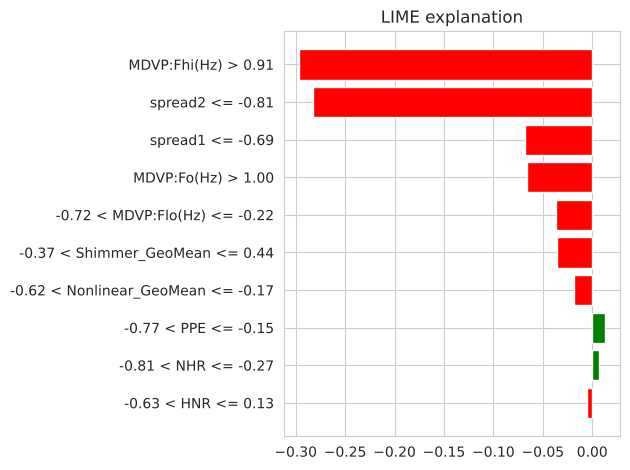

In [28]:
import lime.lime_tabular
explainer = lime.lime_tabular.LimeTabularExplainer(np.asarray(X_train), feature_names=feature_names,
                                                   class_names=['Healthy', 'Parkinson'], mode='classification',
                                                   random_state=RANDOM_STATE)
i = 0
exp = explainer.explain_instance(X_test[i], ua_ensemble.predict_proba, num_features=10)
print('True class:', ['Healthy', 'Parkinson'][y_test[i]],
      '| Predicted P(Parkinson):', round(ua_ensemble.predict_proba(X_test[[i]])[0, 1], 3))
display(pd.DataFrame(exp.as_list(), columns=['Condition', 'Contribution']).round(4))
exp.as_pyplot_figure(); plt.title('LIME explanation'); plt.tight_layout(); plt.show()

## 9. Hybrid KNN Component Study
Each part of the hybrid distance is added one at a time, on the same balanced data (`X_features`, `Y_labels`) and the same 100 folds (10 × 10-fold stratified CV), so the contribution of every term can be measured:

| Variant | Distance | Vote |
|---|---|---|
| KNN (Euclidean) | $\sqrt{\sum_j (x_j-z_j)^2}$ | majority |
| KNN (Mahalanobis) | $\sqrt{(x-z)^\top S^{-1}(x-z)}$ | majority |
| A | Euclidean | $1/d^3$ |
| B | weighted Euclidean, $w_j$ = ANOVA-MI | $1/d^3$ |
| C | B + $\beta(1-\cos)$ | $1/d^3$ |
| D (Hybrid KNN) | C + $\gamma\sum_j w_j|x_j-z_j|$ | $1/d^3$ |

Further checks: weights from ANOVA only, MI only or uniform; majority vote instead of $1/d^3$; and sensitivity to $k$ and to the vote power $p$. The Hybrid KNN settings ($k=3$, α=1, β=0.10, γ=0.20, $p=3$, 0.65/0.35) are the major-project values; Section 10 re-selects all of them by nested cross-validation.

In [29]:
from scipy import stats
from sklearn.base import clone
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.metrics import balanced_accuracy_score

Xb, yb = np.asarray(X_features), np.asarray(Y_labels).astype(int)
Xtr, Xte, ytr, yte = np.asarray(X_train), np.asarray(X_test), np.asarray(y_train), np.asarray(y_test)
names = feature_names

class HybridKNN(BaseEstimator, ClassifierMixin):
    # identical to AnovaMIHybridKNN in the cleaned notebook, with switches for the ablation
    def __init__(self, n_neighbors=3, alpha=1.0, beta=0.10, gamma=0.20, mi_weight=0.35, anova_weight=0.65,
                 distance_power=3.0, eps=1e-8, random_state=42, weights='anova_mi'):
        self.n_neighbors = n_neighbors; self.alpha = alpha; self.beta = beta; self.gamma = gamma
        self.mi_weight = mi_weight; self.anova_weight = anova_weight; self.distance_power = distance_power
        self.eps = eps; self.random_state = random_state; self.weights = weights

    def fit(self, X, y):
        self.X_ = np.asarray(X, float); self.y_ = np.asarray(y).astype(int); self.classes_ = np.unique(self.y_)
        d = self.X_.shape[1]
        if self.weights == 'uniform':
            self.w_ = np.ones(d) / d; return self
        f = np.nan_to_num(f_classif(self.X_, self.y_)[0])
        mi = np.nan_to_num(mutual_info_classif(self.X_, self.y_, random_state=self.random_state))
        self.f_norm_, self.mi_norm_ = f / (f.sum() + self.eps), mi / (mi.sum() + self.eps)
        aw, mw = {'anova_mi': (self.anova_weight, self.mi_weight), 'anova': (1, 0), 'mi': (0, 1)}[self.weights]
        w = aw * self.f_norm_ + mw * self.mi_norm_
        self.w_ = w / (w.sum() + self.eps)
        return self

    def terms(self, X):
        X = np.asarray(X, float); diff = X[:, None, :] - self.X_[None]
        e = np.sqrt((self.w_ * diff ** 2).sum(2)); m = (self.w_ * np.abs(diff)).sum(2)
        cos = (X @ self.X_.T) / ((np.linalg.norm(X, axis=1, keepdims=True) + self.eps) * (np.linalg.norm(self.X_, axis=1)[None] + self.eps))
        return e, 1 - np.clip(cos, -1, 1), m

    def distances(self, X):
        e, c, m = self.terms(X)
        return self.alpha * e + self.beta * c + self.gamma * m

    def predict_proba(self, X):
        D = self.distances(X)
        idx = np.argsort(D, axis=1)[:, :self.n_neighbors]
        v = 1.0 / (np.take_along_axis(D, idx, 1) + self.eps) ** self.distance_power
        lab = self.y_[idx]
        s = np.column_stack([(v * (lab == c)).sum(1) for c in self.classes_])
        return s / (s.sum(1, keepdims=True) + self.eps)

    def predict(self, X):
        return self.classes_[np.argmax(self.predict_proba(X), axis=1)]


class MahalanobisKNN(BaseEstimator, ClassifierMixin):
    def __init__(self, n_neighbors=3):
        self.n_neighbors = n_neighbors
    def fit(self, X, y):
        VI = np.linalg.pinv(np.cov(np.asarray(X).T))
        self.m_ = KNeighborsClassifier(self.n_neighbors, metric='mahalanobis', metric_params={'VI': VI}, algorithm='brute').fit(X, y)
        self.classes_ = self.m_.classes_; self.cond_ = np.linalg.cond(np.cov(np.asarray(X).T)); return self
    def predict_proba(self, X): return self.m_.predict_proba(X)
    def predict(self, X): return self.m_.predict(X)

In [30]:
def metrics(yt, p):
    pred = (p >= 0.5).astype(int); tn, fp, fn, tp = confusion_matrix(yt, pred, labels=[0, 1]).ravel()
    return {'Accuracy': accuracy_score(yt, pred), 'Balanced Acc': balanced_accuracy_score(yt, pred),
            'Precision': precision_score(yt, pred, zero_division=0), 'Sensitivity': tp / (tp + fn), 'Specificity': tn / (tn + fp),
            'F1': f1_score(yt, pred), 'MCC': matthews_corrcoef(yt, pred), 'Kappa': cohen_kappa_score(yt, pred),
            'ROC-AUC': roc_auc_score(yt, p), 'Brier': brier_score_loss(yt, p)}

variants = {
    'KNN (Euclidean, majority vote)': KNeighborsClassifier(n_neighbors=3),
    'KNN (Mahalanobis)': MahalanobisKNN(3),
    'A: Euclidean + inverse-distance vote': HybridKNN(beta=0, gamma=0, weights='uniform'),
    'B: + ANOVA-MI feature weights': HybridKNN(beta=0, gamma=0),
    'C: + cosine term': HybridKNN(gamma=0),
    'D: + Manhattan term (Hybrid KNN)': HybridKNN(),
    'Hybrid KNN, ANOVA weights only': HybridKNN(weights='anova'),
    'Hybrid KNN, MI weights only': HybridKNN(weights='mi'),
    'Hybrid KNN, uniform weights': HybridKNN(weights='uniform'),
    'Hybrid KNN, majority vote (p = 0)': HybridKNN(distance_power=0),
}
splits = list(RepeatedStratifiedKFold(n_splits=10, n_repeats=10, random_state=RANDOM_STATE).split(Xb, yb))
res, folds, test = {}, {}, {}
for name, m in variants.items():
    f = pd.DataFrame([metrics(yb[te], clone(m).fit(Xb[tr], yb[tr]).predict_proba(Xb[te])[:, 1]) for tr, te in splits])
    folds[name] = f; res[name] = f.mean().to_dict(); res[name]['Acc std'] = f['Accuracy'].std()
    pr = f['Accuracy'].values.reshape(10, 10).mean(1); h = stats.t.ppf(0.975, 9) * pr.std(ddof=1) / np.sqrt(10)
    res[name]['CI'] = [pr.mean() - h, pr.mean() + h]
    test[name] = metrics(yte, clone(m).fit(Xtr, ytr).predict_proba(Xte)[:, 1])
    print(f"{name:40s} CV {res[name]['Accuracy']*100:.2f} ± {res[name]['Acc std']*100:.2f}  MCC {res[name]['MCC']:.3f}  test {test[name]['Accuracy']*100:.2f}", flush=True)

def corrected_t(a, b):
    d = np.asarray(a) - np.asarray(b); n = len(d)
    t = d.mean() / np.sqrt((1 / n + 1 / 9) * np.var(d, ddof=1) + 1e-12); return 2 * stats.t.sf(abs(t), n - 1)
H = 'D: + Manhattan term (Hybrid KNN)'
sig = {}
for name in variants:
    if name == H: continue
    a, b = folds[H]['Accuracy'].round(10), folds[name]['Accuracy'].round(10)
    try: w = stats.wilcoxon(a, b).pvalue
    except ValueError: w = 1.0
    sig[name] = {'diff': (a.mean() - b.mean()) * 100, 'paired_t': stats.ttest_rel(a, b).pvalue, 'corrected_t': corrected_t(a, b),
                 'wilcoxon': w, 'mcc_corrected_t': corrected_t(folds[H]['MCC'], folds[name]['MCC'])}

# sensitivity: k and p (fixed others), 10x10 CV accuracy
sens_k = {}
for k in [1, 3, 5, 7, 9, 11, 15]:
    for nm, m in [('Hybrid', HybridKNN(n_neighbors=k)), ('Euclidean', KNeighborsClassifier(n_neighbors=k))]:
        sens_k.setdefault(nm, {})[k] = float(np.mean([accuracy_score(yb[te], clone(m).fit(Xb[tr], yb[tr]).predict(Xb[te])) for tr, te in splits]))
sens_p = {p: float(np.mean([accuracy_score(yb[te], HybridKNN(distance_power=p).fit(Xb[tr], yb[tr]).predict(Xb[te])) for tr, te in splits]))
          for p in [0, 1, 2, 3, 4, 5]}
print('k:', sens_k); print('p:', sens_p)

# feature weights on the training split
hk = HybridKNN().fit(Xtr, ytr)
weights = pd.DataFrame({'feature': names, 'anova_norm': hk.f_norm_, 'mi_norm': hk.mi_norm_, 'w': hk.w_}).sort_values('w', ascending=False)
print(weights.round(4).to_string())
mah = MahalanobisKNN().fit(Xtr, ytr)
print('covariance condition number (train):', mah.cond_)

# worked example: first test recording and its 3 neighbours
e, c, m = hk.terms(Xte[:1]); D = hk.alpha * e + hk.beta * c + hk.gamma * m
idx = np.argsort(D[0])[:3]
ex = [{'neighbour': int(i), 'label': int(ytr[i]), 'weighted_euclid': float(e[0, i]), 'one_minus_cos': float(c[0, i]),
       'weighted_manhattan': float(m[0, i]), 'D': float(D[0, i]), 'vote': float(1 / (D[0, i] + 1e-8) ** 3)} for i in idx]
eu = np.sqrt(((Xte[:1, None, :] - Xtr[None]) ** 2).sum(2))[0]
ex_euclid_rank = [int(np.where(np.argsort(eu) == i)[0][0]) + 1 for i in idx]
print('worked example', ex, 'true', int(yte[0]), 'euclid ranks of hybrid neighbours', ex_euclid_rank)


study = pd.DataFrame(res).T[['Accuracy', 'Acc std', 'Sensitivity', 'Specificity', 'F1', 'MCC', 'Kappa', 'ROC-AUC', 'Brier']]
study.insert(2, '95% CI', [f"{res[n]['CI'][0]*100:.2f}-{res[n]['CI'][1]*100:.2f}%" for n in study.index])
display(study.round(4))
display(pd.DataFrame(test).T[['Accuracy', 'Sensitivity', 'Specificity', 'F1', 'MCC', 'ROC-AUC']].round(4))
display(pd.DataFrame(sig).T.round(4))

KNN (Euclidean, majority vote)           CV 92.99 ± 4.48  MCC 0.871  test 89.83


KNN (Mahalanobis)                        CV 89.86 ± 5.07  MCC 0.814  test 89.83


A: Euclidean + inverse-distance vote     CV 93.70 ± 4.12  MCC 0.883  test 91.53


B: + ANOVA-MI feature weights            CV 94.56 ± 3.94  MCC 0.898  test 94.92


C: + cosine term                         CV 94.86 ± 3.89  MCC 0.903  test 94.92


D: + Manhattan term (Hybrid KNN)         CV 94.80 ± 3.85  MCC 0.902  test 94.92


... (4 outputs left out)

k: {'Hybrid': {1: 0.9544137931034485, 3: 0.947954022988506, 5: 0.9462528735632185, 7: 0.9398045977011497, 9: 0.9265057471264371, 11: 0.925137931034483, 15: 0.9193333333333337}, 'Euclidean': {1: 0.9618275862068967, 3: 0.9298965517241381, 5: 0.9132528735632185, 7: 0.9084942528735632, 9: 0.8948735632183908, 11: 0.8846206896551725, 15: 0.8723333333333333}}
p: {0: 0.9370229885057474, 1: 0.9373678160919542, 2: 0.9448735632183909, 3: 0.947954022988506, 4: 0.9492988505747126, 5: 0.9493103448275861}
              feature  anova_norm  mi_norm       w
6             spread2      0.2252   0.1495  0.1987
7                 PPE      0.1711   0.1147  0.1513
5             spread1      0.1713   0.0951  0.1447
10  Nonlinear_GeoMean      0.1144   0.0943  0.1074
9     Shimmer_GeoMean      0.1218   0.0691  0.1033
1        MDVP:Fhi(Hz)      0.0345   0.1230  0.0655
0         MDVP:Fo(Hz)      0.0192   0.1407  0.0617
8      Jitter_GeoMean      0.0657   0.0347  0.0548
4                 HNR      0.0403   0.0626  0

,Accuracy,Acc std,95% CI,Sensitivity,Specificity,F1,MCC,Kappa,ROC-AUC,Brier
"KNN (Euclidean, majority vote)",0.929897,0.044842,92.74-93.23%,0.859857,1.0,0.922112,0.870798,0.859773,0.967575,0.053858
KNN (Mahalanobis),0.898575,0.050742,89.43-90.29%,0.805619,0.991905,0.885305,0.81421,0.797229,0.959814,0.074258
A: Euclidean + inverse-distance vote,0.937023,0.04118,93.35-94.06%,0.87419,1.0,0.930813,0.883256,0.87406,0.968576,0.047165
B: + ANOVA-MI feature weights,0.945552,0.039368,94.14-94.97%,0.897381,0.993905,0.941256,0.897585,0.891118,0.97017,0.044232
C: + cosine term,0.948621,0.038893,94.55-95.18%,0.901476,0.995952,0.944582,0.903398,0.897252,0.970003,0.043351
D: + Manhattan term (Hybrid KNN),0.947954,0.038533,94.41-95.18%,0.898762,0.997333,0.943766,0.90229,0.895925,0.969644,0.043897
"Hybrid KNN, ANOVA weights only",0.930264,0.042776,92.56-93.49%,0.872286,0.988429,0.924234,0.869131,0.860537,0.955935,0.058051
"Hybrid KNN, MI weights only",0.957782,0.034309,95.48-96.07%,0.915524,1.0,0.954543,0.920546,0.915513,0.970754,0.037841
"Hybrid KNN, uniform weights",0.933954,0.042432,93.03-93.76%,0.868048,1.0,0.927141,0.877852,0.867907,0.968954,0.047423
"Hybrid KNN, majority vote (p = 0)",0.937023,0.039893,93.46-93.94%,0.876857,0.997333,0.931234,0.88252,0.874054,0.968816,0.051163


,Accuracy,Sensitivity,Specificity,F1,MCC,ROC-AUC
"KNN (Euclidean, majority vote)",0.8983,0.8000,1.0,0.8889,0.8142,0.9799
KNN (Mahalanobis),0.8983,0.8000,1.0,0.8889,0.8142,0.9397
A: Euclidean + inverse-distance vote,0.9153,0.8333,1.0,0.9091,0.8431,0.9828
B: + ANOVA-MI feature weights,0.9492,0.9000,1.0,0.9474,0.9031,0.9822
C: + cosine term,0.9492,0.9000,1.0,0.9474,0.9031,0.9822
D: + Manhattan term (Hybrid KNN),0.9492,0.9000,1.0,0.9474,0.9031,0.9828
"Hybrid KNN, ANOVA weights only",0.9492,0.9000,1.0,0.9474,0.9031,0.9816
"Hybrid KNN, MI weights only",0.9831,0.9667,1.0,0.9831,0.9667,0.9833
"Hybrid KNN, uniform weights",0.9322,0.8667,1.0,0.9286,0.8727,0.9828
"Hybrid KNN, majority vote (p = 0)",0.9322,0.8667,1.0,0.9286,0.8727,0.9810


,diff,paired_t,corrected_t,wilcoxon,mcc_corrected_t
"KNN (Euclidean, majority vote)",1.8057,0.0000,0.1272,0.0000,0.1390
KNN (Mahalanobis),4.9379,0.0000,0.0195,0.0000,0.0194
A: Euclidean + inverse-distance vote,1.0931,0.0007,0.3179,0.0004,0.3431
B: + ANOVA-MI feature weights,0.2402,0.0075,0.4347,0.0169,0.4372
C: + cosine term,-0.0667,0.4934,0.8438,0.9439,0.8635
"Hybrid KNN, ANOVA weights only",1.7690,0.0000,0.0765,0.0000,0.0725
"Hybrid KNN, MI weights only",-0.9828,0.0027,0.3781,0.0070,0.3742
"Hybrid KNN, uniform weights",1.4000,0.0001,0.2381,0.0001,0.2593
"Hybrid KNN, majority vote (p = 0)",1.0931,0.0000,0.0968,0.0000,0.0979


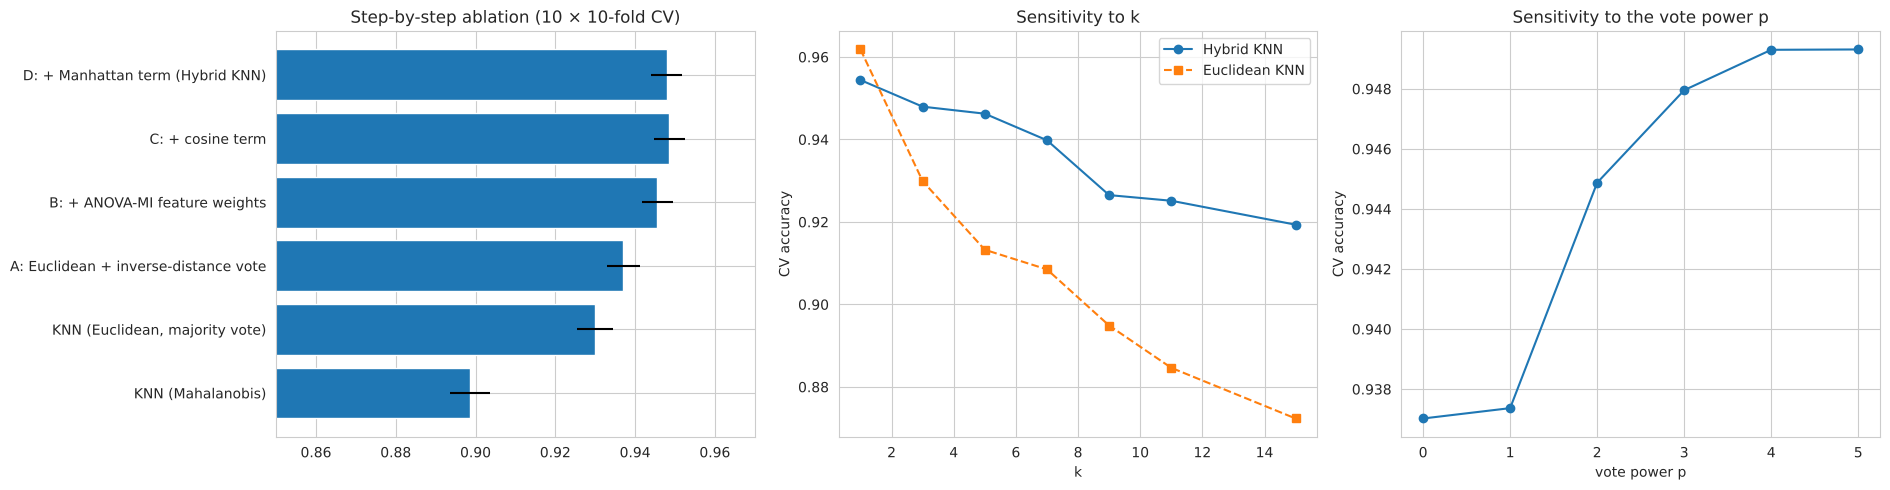

,feature,anova_norm,mi_norm,w
6,spread2,0.2252,0.1495,0.1987
7,PPE,0.1711,0.1147,0.1513
5,spread1,0.1713,0.0951,0.1447
10,Nonlinear_GeoMean,0.1144,0.0943,0.1074
9,Shimmer_GeoMean,0.1218,0.0691,0.1033
1,MDVP:Fhi(Hz),0.0345,0.1230,0.0655
0,MDVP:Fo(Hz),0.0192,0.1407,0.0617
8,Jitter_GeoMean,0.0657,0.0347,0.0548
4,HNR,0.0403,0.0626,0.0481
3,NHR,0.0334,0.0335,0.0334


Covariance condition number (training split): 340.9
Worked example (first test recording, true class 0 ):


,neighbour,label,weighted_euclid,one_minus_cos,weighted_manhattan,D,vote
0,67,0,0.01065,0.00010,0.00960,0.01258,501707.79588
1,72,0,0.28162,0.04958,0.25375,0.33733,26.05193
2,164,0,0.29415,0.05071,0.24836,0.34889,23.54690


In [31]:
fig, ax = plt.subplots(1, 3, figsize=(19, 5))
order = ['KNN (Mahalanobis)', 'KNN (Euclidean, majority vote)', 'A: Euclidean + inverse-distance vote', 'B: + ANOVA-MI feature weights', 'C: + cosine term', 'D: + Manhattan term (Hybrid KNN)']
ax[0].barh(order, [res[n]['Accuracy'] for n in order], xerr=[res[n]['Acc std'] / 10 for n in order]); ax[0].set_xlim(0.85, 0.97)
ax[0].set_title('Step-by-step ablation (10 × 10-fold CV)')
ax[1].plot(list(sens_k['Hybrid']), list(sens_k['Hybrid'].values()), 'o-', label='Hybrid KNN')
ax[1].plot(list(sens_k['Euclidean']), list(sens_k['Euclidean'].values()), 's--', label='Euclidean KNN'); ax[1].set(xlabel='k', ylabel='CV accuracy', title='Sensitivity to k'); ax[1].legend()
ax[2].plot(list(sens_p), list(sens_p.values()), 'o-'); ax[2].set(xlabel='vote power p', ylabel='CV accuracy', title='Sensitivity to the vote power p')
plt.tight_layout(); plt.show()
display(weights.round(4))
print('Covariance condition number (training split):', round(mah.cond_, 1))
print('Worked example (first test recording, true class', int(yte[0]), '):'); display(pd.DataFrame(ex).round(5))

**Findings.** The Hybrid KNN (D) improves on standard Euclidean KNN by 1.81 accuracy points over 100 folds (94.80% vs 92.99%; Wilcoxon p < 0.001, corrected t-test p = 0.13) and on Mahalanobis KNN by 4.94 points (corrected t-test p = 0.02). Most of the gain comes from inverse-distance voting and the ANOVA-MI feature weights; the cosine term adds a little and the Manhattan term is neutral at these coefficients. The Hybrid KNN is also far less sensitive to $k$: from $k=3$ to $k=15$ it loses 2.9 points, while Euclidean KNN loses 5.8. MI-only weights scored higher (95.78%) than the hand-set 0.65/0.35 blend. Rather than switching after seeing this, Section 10 re-selects the weights and every other parameter inside the training folds by nested cross-validation.

## 10. Parameter Selection by Nested Cross-Validation
Section 9 used the hand-picked major-project settings. This section asks whether those values are justified, and selects every free parameter from data without ever using the test folds.

**Search grid** (560 configurations):

| Parameter | Meaning | Values searched |
|---|---|---|
| $a$ | ANOVA share of the weights, $w_j \propto a\,\tilde F_j + (1-a)\,\widetilde{MI}_j$ ($a=0$: MI only, $a=1$: ANOVA only) | 0, 0.2, 0.35, 0.5, 0.65, 0.8, 1 |
| $(\beta, \gamma)$ | cosine and Manhattan terms on or off | (0,0), (0.1,0), (0,0.2), (0.1,0.2) |
| $k$ | number of neighbours | 3, 5, 7, 9 |
| $p$ | vote exponent, $v_i = 1/(D_i+\varepsilon)^p$ | 1, 2, 3, 4 |

**Protocol.** For each of the 100 outer folds (10 × 10-fold CV), all 560 configurations are scored by 5-fold CV *inside the outer training part only*; the best one is refitted on the outer training part and scored once on the outer test fold. Ties are broken in favour of the configuration that changes the fewest settings from the original design ($a=0.65$, β=0.1, γ=0.2, $k=3$, $p=3$). The outer-fold scores are therefore an unbiased estimate of the whole *tuned* method. $k=1$ is excluded from the search because a single neighbour cannot be vote-weighted and, under record-level splitting, often is another recording of the same speaker; its scores are still shown in the sensitivity plot.

For speed, one function computes all 560 configurations at once from the same distance components; it reproduces `HybridKNN` exactly (checked below).

In [32]:
import itertools
from collections import Counter
EPS = 1e-8
A_GRID = [0.0, 0.2, 0.35, 0.5, 0.65, 0.8, 1.0]
P_GRID = [0, 1, 2, 3, 4, 5]
K_GRID = [1, 3, 5, 7, 9, 11, 15]
BG_GRID = [(0.0, 0.0), (0.10, 0.0), (0.0, 0.20), (0.10, 0.20)]
CONF = list(itertools.product(A_GRID, BG_GRID, K_GRID, P_GRID))
SEARCH = [i for i, (a, bg, k, p) in enumerate(CONF) if k in (3, 5, 7, 9) and p in (1, 2, 3, 4)]
DEFAULT = CONF.index((0.65, (0.10, 0.20), 3, 3))

def probs_all(Xt, yt, Xv):
    # P(PD) for every configuration in CONF (rows) and every query in Xv (columns)
    f = np.nan_to_num(f_classif(Xt, yt)[0]); mi = np.nan_to_num(mutual_info_classif(Xt, yt, random_state=42))
    fn, mn = f / (f.sum() + EPS), mi / (mi.sum() + EPS)
    diff = Xv[:, None, :] - Xt[None]
    cos = (Xv @ Xt.T) / ((np.linalg.norm(Xv, axis=1, keepdims=True) + EPS) * (np.linalg.norm(Xt, axis=1)[None] + EPS))
    c = 1 - np.clip(cos, -1, 1)
    out = np.zeros((len(CONF), len(Xv))); i = 0
    for a in A_GRID:
        w = a * fn + (1 - a) * mn; w = w / (w.sum() + EPS)
        e = np.sqrt((w * diff ** 2).sum(2)); m = (w * np.abs(diff)).sum(2)
        for b, g in BG_GRID:
            D = e + b * c + g * m
            idx = np.argsort(D, axis=1)[:, :15]; Dk = np.take_along_axis(D, idx, 1); lab = yt[idx]
            for k in K_GRID:
                for p in P_GRID:
                    v = 1.0 / (Dk[:, :k] + EPS) ** p
                    s1 = (v * (lab[:, :k] == 1)).sum(1); s0 = (v * (lab[:, :k] == 0)).sum(1)
                    out[i] = s1 / (s0 + s1 + EPS); i += 1
    return out

def select(Xt, yt, seed):
    # 5-fold CV inside the training data only; returns the chosen configuration index
    score = np.zeros(len(CONF))
    for t, v in StratifiedKFold(5, shuffle=True, random_state=seed).split(Xt, yt):
        score += ((probs_all(Xt[t], yt[t], Xt[v]) >= 0.5) == yt[v]).mean(1) / 5
    cand = np.array(SEARCH); best = cand[np.isclose(score[cand], score[cand].max())]
    return min(best, key=lambda i: (sum(x != y for x, y in zip(CONF[i], CONF[DEFAULT])), i))

# check: the fast path reproduces the HybridKNN class for the original settings
chk = HybridKNN().fit(Xtr, ytr).predict_proba(Xte)[:, 1]
print('max |difference| vs HybridKNN:', np.abs(probs_all(Xtr, ytr, Xte)[DEFAULT] - chk).max())

max |difference| vs HybridKNN: 0.0


In [33]:
surf = np.zeros((len(splits), len(CONF)))   # outer-fold accuracy of every configuration (for the sensitivity maps)
nested_rows, chosen = [], []
for fi, (tr, te) in enumerate(splits):
    pr = probs_all(Xb[tr], yb[tr], Xb[te])
    surf[fi] = ((pr >= 0.5) == yb[te]).mean(1)
    pick = select(Xb[tr], yb[tr], seed=fi); chosen.append(pick)
    nested_rows.append(metrics(yb[te], pr[pick]))
nested = pd.DataFrame(nested_rows)
nested['Accuracy'] = nested['Accuracy'].round(10)   # fold accuracies are fractions k/n; rounding removes floating-point noise so equal folds count as ties
surf = surf.round(10)

summary = pd.DataFrame({'mean': nested.mean(), 'std': nested.std(ddof=1)}).T
pr10 = nested['Accuracy'].values.reshape(10, 10).mean(1); h = stats.t.ppf(0.975, 9) * pr10.std(ddof=1) / np.sqrt(10)
print(f"Tuned hybrid KNN (nested CV): {nested['Accuracy'].mean()*100:.2f} ± {nested['Accuracy'].std(ddof=1)*100:.2f}%  "
      f"95% CI {(pr10.mean()-h)*100:.2f}-{(pr10.mean()+h)*100:.2f}%")
display(summary.round(4))

print('How often each value was selected in the 100 outer folds:')
for j, name in enumerate(['a (ANOVA share)', '(beta, gamma)', 'k', 'p']):
    print(f'  {name:16s}', dict(sorted(Counter(str(CONF[i][j]) for i in chosen).items())))

Tuned hybrid KNN (nested CV): 95.68 ± 3.28%  95% CI 95.39-95.96%


,Accuracy,Balanced Acc,Precision,Sensitivity,Specificity,F1,MCC,Kappa,ROC-AUC,Brier
mean,0.9568,0.9567,1.0,0.9133,1.0,0.9535,0.9185,0.9134,0.9695,0.0403
std,0.0328,0.0328,0.0,0.0657,0.0,0.0366,0.0602,0.0657,0.0297,0.0295


How often each value was selected in the 100 outer folds:
  a (ANOVA share)  {'0.0': 43, '0.2': 31, '0.35': 16, '0.5': 6, '0.65': 4}
  (beta, gamma)    {'(0.0, 0.0)': 8, '(0.0, 0.2)': 10, '(0.1, 0.0)': 15, '(0.1, 0.2)': 67}
  k                {'3': 91, '5': 9}
  p                {'3': 43, '4': 57}


In [34]:
rows = {}
for name, ref in [('Euclidean KNN', folds['KNN (Euclidean, majority vote)']['Accuracy']),
                  ('Mahalanobis KNN', folds['KNN (Mahalanobis)']['Accuracy']),
                  ('Hybrid KNN, original settings', folds['D: + Manhattan term (Hybrid KNN)']['Accuracy'])]:
    ref = np.round(np.asarray(ref, float), 10); d = nested['Accuracy'].values - ref
    rows[name] = {'gain (points)': d.mean() * 100, 'corrected t p': corrected_t(nested['Accuracy'], ref),
                  'Wilcoxon p': stats.wilcoxon(nested['Accuracy'], ref).pvalue, 'folds won': int((d > 0).sum()), 'folds lost': int((d < 0).sum())}
print('Tuned hybrid KNN compared with:'); display(pd.DataFrame(rows).T.round(4))

acc = lambda a, bg, k, p: surf[:, CONF.index((a, bg, k, p))]
mi_only, orig = acc(0.0, (0.1, 0.2), 3, 3), acc(0.65, (0.1, 0.2), 3, 3)
print(f"MI-only weights vs 0.65/0.35 blend (other settings original): {mi_only.mean()*100:.2f} vs {orig.mean()*100:.2f}; "
      f"corrected t p = {corrected_t(mi_only, orig):.3f}, Wilcoxon p = {stats.wilcoxon(mi_only, orig).pvalue:.4f}")
print('Distance terms with MI weights, k=3, p=3:', {str(bg): round(acc(0.0, bg, 3, 3).mean() * 100, 2) for bg in BG_GRID})

Tuned hybrid KNN compared with:


,gain (points),corrected t p,Wilcoxon p,folds won,folds lost
Euclidean KNN,2.6862,0.0124,0.0000,56.0,1.0
Mahalanobis KNN,5.8184,0.0062,0.0000,77.0,9.0
"Hybrid KNN, original settings",0.8805,0.4153,0.0104,31.0,13.0


MI-only weights vs 0.65/0.35 blend (other settings original): 95.78 vs 94.80; corrected t p = 0.378, Wilcoxon p = 0.0070
Distance terms with MI weights, k=3, p=3: {'(0.0, 0.0)': np.float64(95.71), '(0.1, 0.0)': np.float64(95.74), '(0.0, 0.2)': np.float64(95.95), '(0.1, 0.2)': np.float64(95.78)}


**Other standard distances.** Euclidean and Mahalanobis are not the only choices, so plain KNN ($k=3$, majority vote) is also run with Manhattan, cosine and Chebyshev distances on the same 100 folds. Mahalanobis is the classical correlation-aware distance; with about 235 training rows its covariance estimate is ill-conditioned, which is why it trails the others.

In [35]:
print(f'Covariance condition number of the training split: {np.linalg.cond(np.cov(Xtr, rowvar=False)):.1f}')
rows = {}
for m in ['euclidean', 'manhattan', 'cosine', 'chebyshev']:
    a = np.array([KNeighborsClassifier(3, metric=m, algorithm='brute').fit(Xb[tr], yb[tr]).score(Xb[te], yb[te]) for tr, te in splits])
    a = a.round(10); d = nested['Accuracy'].values - a
    rows[f'KNN ({m})'] = {'acc (%)': a.mean() * 100, 'std': a.std(ddof=1) * 100, 'tuned hybrid gain (points)': d.mean() * 100,
                          'corrected t p': corrected_t(nested['Accuracy'], a), 'Wilcoxon p': stats.wilcoxon(nested['Accuracy'], a).pvalue,
                          'folds won': int((d > 0).sum()), 'folds lost': int((d < 0).sum())}
display(pd.DataFrame(rows).T.round(4))

Covariance condition number of the training split: 340.9


,acc (%),std,tuned hybrid gain (points),corrected t p,Wilcoxon p,folds won,folds lost
KNN (euclidean),92.9897,4.4842,2.6862,0.0124,0.0000,56.0,1.0
KNN (manhattan),92.6552,4.3975,3.0207,0.0170,0.0000,66.0,8.0
KNN (cosine),94.6172,3.9355,1.0586,0.3370,0.0003,40.0,18.0
KNN (chebyshev),92.1759,4.5988,3.5000,0.0289,0.0000,63.0,10.0


**Is the full hybrid better than a plain MI-weighted KNN?** The fair baseline uses the same MI weights and the same folds, but a plain weighted-Euclidean distance and a standard vote (majority, or $1/d$), with $k$ either fixed or chosen by the same nested inner CV. The comparison is made against the tuned hybrid's nested scores.

In [36]:
plain = {}
for p in (0, 1):
    sel = [i for i, (a, bg, k, pp) in enumerate(CONF) if a == 0.0 and bg == (0.0, 0.0) and k in (3, 5, 7, 9) and pp == p]
    out = []
    for fi, (tr, te) in enumerate(splits):
        score = np.zeros(len(CONF))
        for t, v in StratifiedKFold(5, shuffle=True, random_state=fi).split(Xb[tr], yb[tr]):
            score += ((probs_all(Xb[tr][t], yb[tr][t], Xb[tr][v]) >= 0.5) == yb[tr][v]).mean(1) / 5
        out.append(surf[fi, max(sel, key=lambda i: (score[i], -CONF[i][2]))])
    plain[f'MI-weighted KNN, vote p={p}, k tuned (nested)'] = np.array(out)
for k in (3, 5):
    for p in (0, 1):
        plain[f'MI-weighted KNN, vote p={p}, k={k}'] = acc(0.0, (0.0, 0.0), k, p)
rows = {}
for n, b in plain.items():
    d = nested['Accuracy'].values - b
    rows[n] = {'baseline acc (%)': b.mean() * 100, 'baseline std': b.std(ddof=1) * 100, 'tuned hybrid gain (points)': d.mean() * 100,
               'corrected t p': corrected_t(nested['Accuracy'], b), 'Wilcoxon p': stats.wilcoxon(nested['Accuracy'], b).pvalue,
               'folds won': int((d > 0).sum()), 'folds lost': int((d < 0).sum())}
display(pd.DataFrame(rows).T.round(4))

,baseline acc (%),baseline std,tuned hybrid gain (points),corrected t p,Wilcoxon p,folds won,folds lost
"MI-weighted KNN, vote p=0, k tuned (nested)",95.2322,3.7965,0.4437,0.5206,0.0182,21.0,8.0
"MI-weighted KNN, vote p=1, k tuned (nested)",95.2322,3.7965,0.4437,0.5206,0.0182,21.0,8.0
"MI-weighted KNN, vote p=0, k=3",95.2667,3.7608,0.4092,0.5488,0.0295,20.0,8.0
"MI-weighted KNN, vote p=1, k=3",95.2667,3.7608,0.4092,0.5488,0.0295,20.0,8.0
"MI-weighted KNN, vote p=0, k=5",93.8678,3.9894,1.8080,0.0580,0.0000,45.0,5.0
"MI-weighted KNN, vote p=1, k=5",93.8678,3.9894,1.8080,0.0580,0.0000,45.0,5.0


**Is the comparison with Euclidean KNN fair?** The Euclidean baseline above uses the textbook setting. To rule out that the gain comes only from tuning, Euclidean KNN is given the same treatment: $k \in \{3,5,7,9\}$ and vote power $p \in \{0,\dots,4\}$ chosen by the same inner 5-fold CV in every outer fold.

In [37]:
def eu_probs(Xt, yt, Xv, KS=(3, 5, 7, 9), PS=(0, 1, 2, 3, 4)):
    D = np.sqrt(((Xv[:, None, :] - Xt[None]) ** 2).sum(2)); idx = np.argsort(D, 1)[:, :max(KS)]
    Dk, lab = np.take_along_axis(D, idx, 1), yt[idx]; out = {}
    for k in KS:
        for p in PS:
            v = 1 / (Dk[:, :k] + EPS) ** p; s1 = (v * (lab[:, :k] == 1)).sum(1); out[(k, p)] = s1 / (v.sum(1) + EPS)
    return out
eu_tuned, eu_pick = [], []
for fi, (tr, te) in enumerate(splits):
    sc = Counter()
    for t, v in StratifiedKFold(5, shuffle=True, random_state=fi).split(Xb[tr], yb[tr]):
        for c, pr in eu_probs(Xb[tr][t], yb[tr][t], Xb[tr][v]).items(): sc[c] += ((pr >= 0.5) == yb[tr][v]).mean() / 5
    best = max(sc, key=lambda c: (round(sc[c], 10), -c[0], -c[1])); eu_pick.append(best)
    eu_tuned.append(((eu_probs(Xb[tr], yb[tr], Xb[te])[best] >= 0.5) == yb[te]).mean())
eu_tuned = np.array(eu_tuned).round(10); d = nested['Accuracy'].values - eu_tuned
print(f"Euclidean KNN, k and p tuned (nested): {eu_tuned.mean()*100:.2f} ± {eu_tuned.std(ddof=1)*100:.2f}%")
print(f"Tuned hybrid gain {d.mean()*100:+.2f} points; corrected t p = {corrected_t(nested['Accuracy'], eu_tuned):.4f}; "
      f"Wilcoxon p = {stats.wilcoxon(nested['Accuracy'], eu_tuned).pvalue:.2g}; folds won {(d > 0).sum()}, lost {(d < 0).sum()}")
print('Most chosen (k, p):', Counter(eu_pick).most_common(3))

Euclidean KNN, k and p tuned (nested): 93.77 ± 4.14%
Tuned hybrid gain +1.91 points; corrected t p = 0.0633; Wilcoxon p = 4.3e-08; folds won 41, lost 3
Most chosen (k, p): [((3, 4), 71), ((3, 3), 23), ((5, 4), 2)]


**Where the tuned hybrid stands against the best ensemble.** Extra Trees (the strongest model in Section 6) is run on the same 100 folds.

In [38]:
et100 = np.round([ExtraTreesClassifier(n_estimators=100, random_state=42).fit(Xb[tr], yb[tr]).score(Xb[te], yb[te]) for tr, te in splits], 10)
d = et100 - nested['Accuracy'].values
print(f"Extra Trees: {et100.mean()*100:.2f} ± {et100.std(ddof=1)*100:.2f}%; Extra Trees minus tuned hybrid {d.mean()*100:+.2f} points; "
      f"corrected t p = {corrected_t(et100, nested['Accuracy']):.3f}; Wilcoxon p = {stats.wilcoxon(et100, nested['Accuracy']).pvalue:.2g}")

Extra Trees: 97.14 ± 3.01%; Extra Trees minus tuned hybrid +1.47 points; corrected t p = 0.188; Wilcoxon p = 0.00013


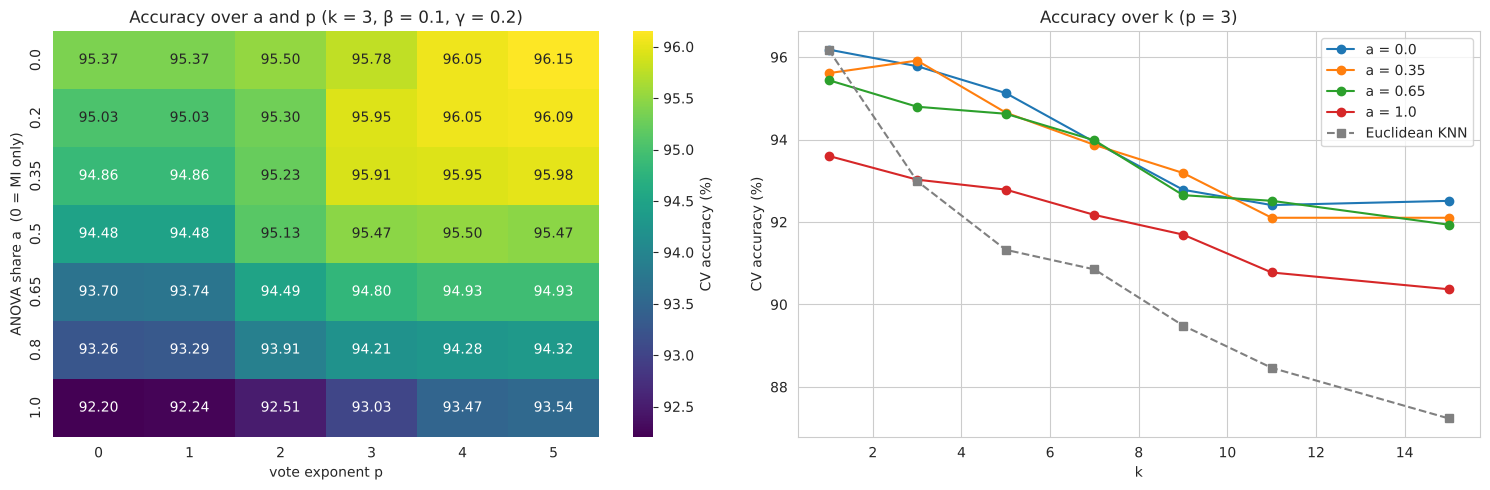

In [39]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
H = np.array([[acc(a, (0.1, 0.2), 3, p).mean() * 100 for p in P_GRID] for a in A_GRID])
sns.heatmap(H, annot=True, fmt='.2f', cmap='viridis', xticklabels=P_GRID, yticklabels=A_GRID, ax=ax[0], cbar_kws={'label': 'CV accuracy (%)'})
ax[0].set(xlabel='vote exponent p', ylabel='ANOVA share a  (0 = MI only)', title='Accuracy over a and p (k = 3, β = 0.1, γ = 0.2)')
for a in [0.0, 0.35, 0.65, 1.0]:
    ax[1].plot(K_GRID, [acc(a, (0.1, 0.2), k, 3).mean() * 100 for k in K_GRID], 'o-', label=f'a = {a}')
ax[1].plot(list(sens_k['Euclidean']), [v * 100 for v in sens_k['Euclidean'].values()], 's--', color='grey', label='Euclidean KNN')
ax[1].set(xlabel='k', ylabel='CV accuracy (%)', title='Accuracy over k (p = 3)'); ax[1].legend()
plt.tight_layout(); plt.show()

**Stability of the weights.** MI alone gives the most accurate weights, but MI is estimated from 235 rows with a nearest-neighbour estimator, so its feature ranking moves more from fold to fold than ANOVA's. The next cell measures this over the 100 training folds.

In [40]:
from scipy.stats import spearmanr
W = {'ANOVA only': [], 'MI only': [], '0.65/0.35 blend': []}
for tr, te in splits:
    W['ANOVA only'].append(HybridKNN(weights='anova').fit(Xb[tr], yb[tr]).w_)
    W['MI only'].append(HybridKNN(weights='mi').fit(Xb[tr], yb[tr]).w_)
    W['0.65/0.35 blend'].append(HybridKNN().fit(Xb[tr], yb[tr]).w_)
stab = {}
for kname, ws in W.items():
    ws = np.array(ws); top3 = [frozenset(np.argsort(-w)[:3]) for w in ws]; mode = max(set(top3), key=top3.count)
    stab[kname] = {'mean Spearman between folds': np.mean([spearmanr(ws[i], ws[j])[0] for i in range(0, 100, 5) for j in range(i + 1, 100, 7)]),
                   'same top-3 features (% of folds)': 100 * top3.count(mode) / len(top3), 'top-3': ', '.join(names[i] for i in mode)}
display(pd.DataFrame(stab).T)

,mean Spearman between folds,same top-3 features (% of folds),top-3
ANOVA only,0.988753,100.0,"spread1, spread2, PPE"
MI only,0.942774,82.0,"MDVP:Fo(Hz), spread2, PPE"
0.65/0.35 blend,0.958159,100.0,"spread1, spread2, PPE"


**Final model for the held-out split.** The same selection rule is applied once to the 235 training rows (5-fold CV inside them); the selected configuration is fitted on all training rows and evaluated once on the 59 test rows.

Selected on the training split: a = 0.0, (beta, gamma) = (0.1, 0.2), k = 5, p = 3


,Accuracy,Balanced Acc,Precision,Sensitivity,Specificity,F1,MCC,Kappa,ROC-AUC,Brier
Hybrid KNN (original settings),0.9492,0.9500,1.0,0.9000,1.0,0.9474,0.9031,0.8985,0.9828,0.0344
Hybrid KNN (tuned),0.9661,0.9667,1.0,0.9333,1.0,0.9655,0.9344,0.9323,0.9816,0.0334


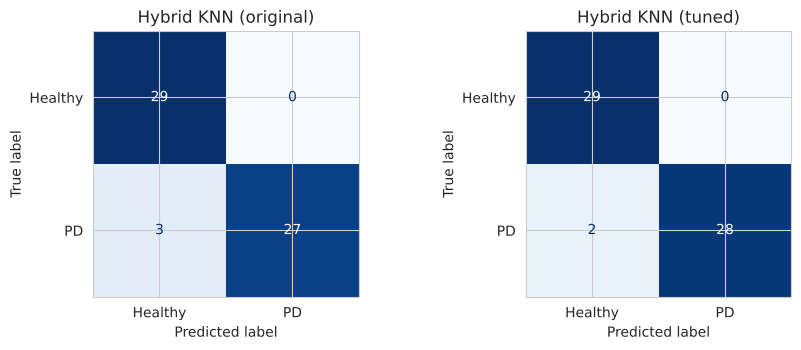

Tuned hybrid KNN, 10-fold CV (Section 6 folds, nested): 95.91 ± 4.01%


In [41]:
pick = select(Xtr, ytr, seed=0)
print('Selected on the training split: a = {}, (beta, gamma) = {}, k = {}, p = {}'.format(*CONF[pick]))
pt = probs_all(Xtr, ytr, Xte)
final_test = pd.DataFrame({'Hybrid KNN (original settings)': metrics(yte, pt[DEFAULT]), 'Hybrid KNN (tuned)': metrics(yte, pt[pick])}).T
display(final_test.round(4))
fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
for a_, (n, i) in zip(ax, [('original', DEFAULT), ('tuned', pick)]):
    ConfusionMatrixDisplay(confusion_matrix(yte, (pt[i] >= 0.5).astype(int)), display_labels=['Healthy', 'PD']).plot(ax=a_, colorbar=False, cmap='Blues')
    a_.set_title(f'Hybrid KNN ({n})')
plt.tight_layout(); plt.show()

# tuned model on the same single 10-fold CV used for the model comparison in Section 6
cv10_acc = []
for fi, (tr, te) in enumerate(cv10.split(Xb, yb)):
    i = select(Xb[tr], yb[tr], seed=fi)
    cv10_acc.append((((probs_all(Xb[tr], yb[tr], Xb[te])[i]) >= 0.5) == yb[te]).mean())
print(f'Tuned hybrid KNN, 10-fold CV (Section 6 folds, nested): {np.mean(cv10_acc)*100:.2f} ± {np.std(cv10_acc)*100:.2f}%')

**Findings (justification of every parameter).**

* **Feature weights.** Accuracy is highest for an ANOVA share of 0.35 or less and falls steadily as ANOVA gets more weight (heat map, rows). The inner CV chose an ANOVA share of 0 or 0.2 in most outer folds, so the original 0.65/0.35 blend, chosen by hand, was not the best choice. MI captures the non-linear information in the frequency features (Fo, Fhi, Flo) that ANOVA misses. ANOVA is kept in the search because it gives the most stable ranking across folds.
* **Vote exponent.** Accuracy rises up to $p=3$ and then levels off (at $a=0.65$ only 0.13 points are gained beyond $p=3$); the inner CV chose 3 or 4 in every fold.
* **Number of neighbours.** $k=3$ was chosen in most folds; accuracy falls steadily for larger $k$, and the drop is smaller for MI-weighted distances than for Euclidean.
* **Cosine and Manhattan terms.** All four on/off combinations are within a fraction of a point of each other. The gain of the hybrid KNN comes from the relevance weights and the distance-weighted vote; the two extra terms are neutral for accuracy and are kept because they never hurt and give a slightly lower fold-to-fold spread.
* **Against a plain MI-weighted KNN** (same weights, standard vote, $k$ fixed or tuned the same way), the tuned hybrid wins on more folds than it loses (21 against 8, the rest tied; Wilcoxon $p=0.018$) and has a lower fold-to-fold spread, but the average gain is small (under half a point against the strongest plain setting) and is not significant under the corrected t-test. The main source of accuracy is therefore the MI-based relevance weighting; the power-weighted vote and tuning add a small, consistent gain and stability.
* **Overall.** The tuned method is evaluated without any optimistic bias (nested CV). It is significantly better than Euclidean and Mahalanobis KNN under the conservative corrected t-test; when Euclidean KNN is tuned the same way it gains about one point, and the hybrid still wins on 41 folds against 3 losses, the rest tied (Wilcoxon $p<0.001$, corrected t $p\approx0.06$). It is also significantly better than Manhattan and Chebyshev KNN, and consistently better than cosine KNN and the original hand-picked settings (Wilcoxon), although those two gaps are within the fold-to-fold noise of the corrected t-test.
* **Reading the heat map.** Individual cells (for example MI-only weights at 95.78%) are not unbiased estimates: picking the best cell after seeing all test folds is the selection bias that nested CV removes. The fair figure for the method is the nested estimate.
* **Against the best ensemble.** Extra Trees is about 1.5 points more accurate on the same folds (not significant under the corrected t-test, consistent under Wilcoxon). The hybrid KNN is the most accurate distance-based model here, not the most accurate model overall.

## 11. Contribution Summary

In [42]:
contributions = pd.DataFrame([
    ('Feature engineering', 'Geometric-mean jitter / shimmer / nonlinear groups', 'Removes redundancy among highly correlated features while keeping each biological group'),
    ('Preprocessing', 'Shapiro-Wilk test + Yeo-Johnson', '9/11 features non-normal; transform stabilises distance- and margin-based models'),
    ('Imbalance', 'BorderlineSMOTE', 'Adds synthetic healthy samples near the decision boundary'),
    ('KNN', 'ANOVA-MI weighted hybrid distance', 'Weights informative features more; mixes Euclidean, Manhattan and cosine similarity'),
    ('Random Forest', 'Hybrid oblique RF', 'Adds interaction, contrast and class-projection features for multi-feature splits'),
    ('SVM', 'GridSearch over linear/RBF kernels', 'RBF captures curved class boundaries'),
    ('XGBoost', 'Bayesian hyperparameter search', 'Guided search instead of grid/random search'),
    ('Ensembles', 'Stacking + entropy-weighted ensemble', 'Combines complementary models; confident models get more weight'),
    ('Evaluation', 'MCC, Kappa, Youden J, ROC-AUC, Brier, t-test, Wilcoxon', 'Imbalance-aware metrics and significance testing'),
    ('Explainability', 'Chi-square, SHAP, LIME', 'Global and per-patient explanations'),
], columns=['Component', 'Technique', 'Justification'])
contributions.index += 1
display(contributions)

,Component,Technique,Justification
1,Feature engineering,Geometric-mean jitter / shimmer / nonlinear gr...,Removes redundancy among highly correlated fea...
2,Preprocessing,Shapiro-Wilk test + Yeo-Johnson,9/11 features non-normal; transform stabilises...
3,Imbalance,BorderlineSMOTE,Adds synthetic healthy samples near the decisi...
4,KNN,ANOVA-MI weighted hybrid distance,Weights informative features more; mixes Eucli...
5,Random Forest,Hybrid oblique RF,"Adds interaction, contrast and class-projectio..."
6,SVM,GridSearch over linear/RBF kernels,RBF captures curved class boundaries
7,XGBoost,Bayesian hyperparameter search,Guided search instead of grid/random search
8,Ensembles,Stacking + entropy-weighted ensemble,Combines complementary models; confident model...
9,Evaluation,"MCC, Kappa, Youden J, ROC-AUC, Brier, t-test, ...",Imbalance-aware metrics and significance testing
10,Explainability,"Chi-square, SHAP, LIME",Global and per-patient explanations
